# **STEP 4, PART 1.5**

### **The choices the Bayesian step has to make: Mask policy, the north-south normalization, the hyper-parameters of `huber_sc`, the noise of the surrogate, the priors, and a closed-loop test on fake skies**

In the last notebooks, we made observations over how the gain of the asymmetric model compares with the symmetric best-fit `G1`. Although, without the Bayesian step (step 5), we cannot trust these values as they are, we can consider trends. We see that one-sided masks and the north-south normalization can constitute a large part of the gain, leaving a small part for wind to play on the shape. However, a negative $v_{\rm motion}$ in most residuals with some amount of negative gain is the trend we take away.

In this notebook, we turn those observations into questions: which mask policy, which treatment of the normalization, which likelihood, and which hyper-parameters, how much to trust the surrogate, which prior, and whether the whole pipeline can separate a wind from a mask and a normalization at all.

| section | question | needs |
|---|---|---|
| 1. Geometry | which voxels does each mask policy keep? (`as_is`, `OA`, `boxes`, `mirror`, and the single boxes) | LAB |
| 2. The cache | model values of `G1`, `M1`, `B1` (+ `PR2`) on the comparison grid, once | the packs |
| 3. The evaluator | one function for every residual, policy and normalization; checked against the stored residuals | cache |
| 4. Mask policy | the gain of `M1 / B1` over `G1` per policy and per box, the hemisphere trade, the refit of $v_{\rm motion}$ and of $\theta$ | cache; fits |
| 5. Normalization | one scale, own scales, a free ratio, an informative prior on $\ln(s_S/s_N)$: what each does to $v_{\rm motion}$ | cache; fits |
| 6. Likelihood | $(\sigma_0, \epsilon, k)$ of `huber_sc` one at a time; voxel Huber tempered by $N_{\rm eff}$ against Huber on blocks; how many nats the wind is worth | cache; fits |
| 7. The surrogate | heavy tails and heteroscedasticity of the run noise; a robust refit; the two modes | fits |
| 8. Priors and box | where the optima sit relative to the box; the prior on $v_{\rm motion}$ implied by a 10-300 Myr build-up | fits |
| 9. Closed loop | fake skies with a known wind, a known normalization difference and a mask artefact: does the pipeline recover them? | cache; fits |

## 0. Settings

In [1]:
import sys, re, json, pickle, time, os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import nnls

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

import grid_search as g
import grid_search_residuals as gr
import pack_grid as pg

# ---------------- where things are ----------------
WORK        = Path("./")                       # the step-4 folder: out_<STAGE>_*/, results_<STAGE>/, runs/
G1_DIR      = Path("../Grid_Search/results")   # the results folder of the symmetric grid search (G1)
G1_WORK     = G1_DIR.parent                    # its out_G1_*/, out_P1_*/, runs/
LAB_PATH    = "../Displays/lab.fit.gz"
PRODUCTS    = "../Convergence/lab_products.npz"
SFR_PROFILE = "../Tests/inputs/sfr_profile_marasco12.txt"
CONV        = Path("../Convergence/conv")
WORKERS     = 10
HERON_WORK  = "<redacted_for_privacy>"
PROBE_MIN, PROBE_MB, PROBE_N = 5.81, 1050.0, 40   # the time of the G1 job (an asymmetric model is x2 in gr.job_estimate) and the memory estimate of the asymmetric grid notebooks
HV0_MAX     = 120.0                            # the box of the grid searches
DIAG        = WORK / "diag_cache"              # everything this notebook writes (merged packs, fits, tables) goes here, never into the folders of the grid searches
DIAG.mkdir(exist_ok=True)

# ---------------- the stages ----------------
SYM  = dict(label="G1", stage="G1", check="P1", work=G1_WORK, res=G1_DIR)
ASYM = {"motion": dict(label="motion", stage="M1", check="PM1", work=WORK, res=WORK / "results_M1"),
        "cgm":    dict(label="cgm",    stage="C1", check="PC1", work=WORK, res=WORK / "results_C1"),
        "both":   dict(label="both",   stage="B1", check="PB1", work=WORK, res=WORK / "results_B1")}

# ---------------- the asymmetry of the runs (the same numbers as in the grid-search notebooks) ----------------
T_RATIO      = 1.12
GAMMA        = 5.0 / 3.0
RHO_RATIO    = T_RATIO ** (1.0 / (GAMMA - 1.0))
SOUTH_RATIOS = dict(south_vlag_ratio=T_RATIO, south_alpha_conds_ratio=RHO_RATIO, south_drag_ratio=RHO_RATIO)
V_MOTION_RANGE = (-60.0, 20.0)

# ---------------- the comparison with LAB: the same settings as the grid searches ----------------
B_CUT, L_CUT = 0, 0
V_DEV      = 35.0
REL_FLOOR  = 0.04

In [ ]:
from mw_io import load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions, flat_v_circ,
                     OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)
from marasco_comp import *

def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH, correction=False)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)

SIGMA_NUM  = P.sigma_empty
T_M        = 0.04
K_L        = 2.0
RESIDUAL_SETS = {
    "base": dict(kind="soft"),
    "Mrsc": dict(kind="select", T=T_M, rel="max", blanks=False),
    "Li":   dict(kind="select", k=K_L, sigma=SIGMA_NUM, rel="max", blanks=True),
}
TAG = f"v{V_DEV:g}_L{L_CUT:g}_B{B_CUT:g}_f{REL_FLOOR:g}_T{T_M:g}_k{K_L:g}_s{SIGMA_NUM*1e3:.2f}"

cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full,
                        CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0),
                        rel_floor=REL_FLOOR, residual_sets=RESIDUAL_SETS)
cfg = cmp.cfg
KEYS = list(cmp.keys)
print(f"Residual settings tag {TAG}\nComparison grid {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; keys: {KEYS}")

# the noise of one n = 40 run, per residual (convergence study)
PK_CONV = CONV / f"marasco_conv_{TAG}.pkl"
RES_CONV = pickle.load(open(PK_CONV, "rb")) if PK_CONV.exists() else {}
RES_CONV = {n: r for n, r in RES_CONV.items() if r.get("keys") == KEYS}
GN = {}
for nm in RES_CONV:
    m = re.match(r"N(\d+)_s(\d+)$", nm)
    if m: GN.setdefault(f"N{m[1]}", []).append(nm)
if RES_CONV and len(GN.get("N40", [])) >= 3:
    NOISE = gr.noise_table_from_conv(RES_CONV, GN, KEYS)
else:
    NOISE = {k: dict(gr.NOISE_FALLBACK[k]) for k in KEYS}
S40 = {k: float(gr._interp_noise(NOISE[k], 40)) for k in KEYS}      # relative noise of one n = 40 run

print("Noise of one n = 40 run [%]:", {k: round(100 * S40[k], 2) for k in KEYS})

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: none
Note: correction=False, the stored correction is NOT applied; the stored sigma belongs to the corrected cube.
residual settings tag v35_L0_B0_f0.04_T0.04_k2_s3.12
Comparison grid 62 channels x 41 b x 90 l; keys: ['abs', 'sq', 'rel', 'abs_Mrsc', 'sq_Mrsc', 'rel_Mrsc', 'abs_Li', 'sq_Li', 'rel_Li']
Noise of one n = 40 run [%]: {'abs': 1.26, 'sq': 3.95, 'rel': 0.94, 'abs_Mrsc': 1.35, 'sq_Mrsc': 3.97, 'rel_Mrsc': 1.38, 'abs_Li': 1.31, 'sq_Li': 3.95, 'rel_Li': 1.05}


## 1. Load the stages

For every stage (`G1`, `M1`, `C1`, `B1`) the residual cache `grid_resid_<TAG>.pkl` of its `results` folder is read. Models that the cache does not have yet (the check stages, if their notebook was not run after the job) are evaluated from the pack. The run files give the parameters and the group (stage) of every model.

In [3]:
def load_set(S):
    """ Residuals and runs of one stage and its check stage: S = SYM or one of ASYM. """
    runs = {}
    for f in sorted((S["work"] / "runs").glob("grid4d_*.json")): runs.update(g.load_runs(f))
    runs = {n: r for n, r in runs.items() if r["group"] in (S["stage"], S["check"])}
    cache = S["res"] / f"grid_resid_{TAG}.pkl"                 # read only
    res = {}
    if cache.exists():
        res = {n: r for n, r in pickle.load(open(cache, "rb")).items() if r.get("keys") == KEYS and n in runs}

    missing = [n for n in runs if n not in res]
    if missing:
        pack = get_pack(S["label"], S)
        if pack is None:
            print(f"> {S['label']}: {len(missing)} models are not in the cache and there is no pack: they are left out.")
        else:
            todo = [n for n in missing if n in pack.names]
            new = gr.evaluate_pack(pack, cmp, names=todo, cache=DIAG / f"resid_{S['label']}_{TAG}.pkl", workers=WORKERS)
            res.update(new)
    return res, runs

PACKS = {}
def get_pack(label, S=None):
    """
    The pack of a stage and its check stage (merged into the diagnostics folder, 
    never into the folders of the grid searches).
    """
    if label not in PACKS:
        S = S or STG[label]
        files = sorted(S["work"].glob(f"out_{S['stage']}_*/pack.fits")) + \
                sorted(S["work"].glob(f"out_{S['check']}_*/pack.fits"))
        
        PACKS[label] = gr.open_packs(files, DIAG / f"pack_{label}.fits") if files else None

    return PACKS[label]

STG = {}    # the stages, by label: STG["G1"], STG["motion"], STG["cgm"], STG["both"].
for S in [SYM] + list(ASYM.values()):
    res, runs = load_set(S)
    STG[S["label"]] = dict(S, RES=res, RUNS=runs)
    n_stage = sum(1 for n in res if runs[n]["group"] == S["stage"])
    n_chk = sum(1 for n in res if runs[n]["group"] == S["check"])
    print(f"{S['label']:7s} {S['stage']}: {n_stage:4d} models of the grid, {S['check']}: {n_chk:3d} replicates")

def rep_groups(res, stage):
    """ {place: [model names]} of the replicates of a check stage ('<stage>_<place>_s<k>'). """
    pat = re.compile(rf"^{re.escape(stage)}_(.+)_s(\d+)$"); out = {}
    for n in res:
        m = pat.match(n)
        if m: out.setdefault(m[1], []).append(n)
    return out

for lab_, T in STG.items():
    T["REP"] = rep_groups(T["RES"], T["check"])
    print(f"{lab_:7s} places of {T['check']}: {sorted(T['REP'])}")

# ---- the best model of a stage, and its cubes on the comparison grid (used in sections 4 and 6)
STRUCT_KEY = "abs_Li"

def best_model(label, key=STRUCT_KEY):
    """ 
    The replicate of median R at the stage's own optimum of `key` (representative, not a lucky draw).
    Without the check stage, it is the best grid model.
    """
    T = STG[label]; reps = T["REP"].get(f"opt_{key}", [])
    if reps:
        order = sorted(reps, key=lambda n: T["RES"][n]["R_" + key]); return order[len(order) // 2]
    names = [n for n in T["RES"] if T["RUNS"][n]["group"] == T["stage"]]

    return min(names, key=lambda n: T["RES"][n]["R_" + key])

def field_cubes(label, name):
    """ Data, scaled model and sigma on the comparison cube (NaN where invalid), and the evaluation (with its vectors). """
    mod = get_pack(label).cmp_cube(name)
    ev = cmp.evaluate(mod, keep_vectors=True); vec = ev["vec"]
    shape = cmp.lab_cmp.data.shape
    D = np.full(shape, np.nan); M = np.full(shape, np.nan); W = np.zeros(shape)
    D[vec["valid"]] = vec["d"]; M[vec["valid"]] = vec["m"]; W[vec["valid"]] = vec["w"]
    S = np.full(shape, float(SIGMA_NUM))
    
    return D, M, W, S, ev

G1      G1:  512 models of the grid, P1:  80 replicates
motion  M1:  512 models of the grid, PM1:  80 replicates
cgm     C1:  512 models of the grid, PC1:  80 replicates
both    B1:  512 models of the grid, PB1:  80 replicates
G1      places of P1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
motion  places of PM1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
cgm     places of PC1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
both    places of PB1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']


## 1b. Settings of this notebook

- `POLICY0`: the mask policy used wherever one has to be chosen (sections 5-9). Section 4 compares all of them. 
    * `as_is` = the masks of the grid searches (boxes in one hemisphere); 
    * `OA` = additionally drop the voxels whose mirror image lies in the `OUTER_ARM` box (the north-side box whose south mirror is compared but has no data counterpart); 
    * `boxes` = the same for all four named boxes (`OUTER_ARM`, `GCP`, `EXTERNAL_GAL`, `MAGELLANIC`); 
    * `mirror` = keep a voxel only if the voxel at $-b$ (same $l$, $v$) is also compared, in the data and in the model (this is the policy of the previous notebook; it also removes what the disk-emission mask and the edges do asymmetrically).

- `N_EFF`: effective number of independent voxels (section 6c of the first notebook: 230-280 against 160 304 voxels). A voxel likelihood is tempered by `N_EFF / N`; this changes the weight of a prior against the data, not the position of an optimum.

- `SIG0, EPS, HUBER_K`: the scatter law $s^2 = \sigma_0^2 + \epsilon^2 M^2$ and the Huber threshold of `huber_sc` (as in the likelihoods notebook).
- `LAM`: the grid of $\lambda = \ln \rho$, $\rho = s_S / s_N$, of the normalization family of section 5.

In [4]:
POLICY0   = "OA"                                # "as_is" | "OA" | "boxes" | "mirror"
POLICIES  = ["as_is", "OA", "boxes", "mirror"]  # evaluated for the whole grid of every stage
SINGLES   = ["GCP", "EXT", "MAG"]               # single boxes: evaluated at the replicates only (section 4)
N_EFF     = 250.0
SIG0, EPS, HUBER_K = 0.012, 1.0, 1.5
HP        = (SIG0, EPS, HUBER_K)
BLK       = (4, 4, 4)                           # block in (v, b, l) cells of the comparison grid (32 km/s x 16 deg x 16 deg)
LAM       = np.round(np.arange(-1.2, 1.2001, 0.1), 3)   # ln(s_S / s_N); 0 = one scale for the whole sky
TAB_VARS  = ("huber_sc", "abs_Li")              # variables with a table over LAM
LABELS    = ["G1", "motion", "both"]
FIT_STAGES = ["motion", "both"]                 # stages whose surfaces are fitted in sections 4-6.
V3TAG     = f"{TAG}_s{SIG0 * 1e3:.1f}_e{EPS:g}_h{HUBER_K:g}"

import hashlib
from scipy.interpolate import CubicSpline
print("Policy used where one is needed:", POLICY0, "| N_eff", N_EFF, "| huber_sc:", HP)

Policy used where one is needed: OA | N_eff 250.0 | huber_sc: (0.012, 1.0, 1.5)


## 2. Geometry: the voxels, the mirror partner of each, and the boxes

The comparison grid has $(v, b, l)$ axes. A voxel enters a comparison if LAB is valid there and the model is finite. Each voxel at $(l, b, v)$ has a mirror partner at $(l, -b, v)$. A mask policy drops a voxel when its partner is masked (`mirror`), or when its partner lies inside a named box (`OA`, `boxes`, the single boxes). The boxes are drawn on the comparison grid from the same definitions as the masks (`mw_mask`). The table shows how many voxels each policy loses and where.

In [5]:
obs3 = np.asarray(cmp.lab_cmp.data)
bgrid = np.asarray(cmp.b, float)
shp = obs3.shape

DV = np.isfinite(obs3) & (bgrid != 0)[None, :, None]            # Voxels where LAB is valid (the model may still be masked).
nDV = int(DV.sum()); iv, ib, il = (a.astype(np.int64) for a in np.nonzero(DV))

DATA  = obs3[DV].astype(np.float64)
WGT   = np.asarray(cmp.w_b, float)[ib]
NORTH = bgrid[ib] > 0

jm = np.argmin(np.abs(bgrid[:, None] + bgrid[None, :]), axis=1) # Index of -b.
nz = bgrid != 0

idx3 = np.full(shp, -1, np.int64); idx3[DV] = np.arange(nDV)
PARTNER = idx3[:, jm, :][DV]
# Index (in the DV vector) of the mirror partner, -1 if LAB is not valid there.

BOXES = {"OA": [OUTER_ARM], "GCP": [GCP], "EXT": list(EXTERNAL_GAL), "MAG": list(MAGELLANIC)}
IN3   = {k: mask_named_regions(cmp.l, cmp.b, cmp.v, regs) for k, regs in BOXES.items()}
PIN   = {k: IN3[k][:, jm, :][DV] for k in BOXES}                # The mirror partner of the voxel lies inside the box.
T_LI  = set_threshold(RESIDUAL_SETS["Li"])

print(f"Voxels with LAB valid: {nDV} (north {NORTH.sum()}, south {(~NORTH).sum()}); "
      f"with a mirror partner in the same set: {(PARTNER >= 0).sum()}")
print(f"{'box':5s} {'cells inside':>13s} {'in LAB set':>11s} | "
      f"{'partner inside, voxel in LAB set':>34s} {'north':>8s} {'south':>8s} {'% of the set':>13s}")

for k in BOXES:
    pin = PIN[k]
    print(f"{k:5s} {int(IN3[k].sum()):13d} {int((IN3[k] & DV).sum()):11d} | "
          f"{int(pin.sum()):34d} {int((pin & NORTH).sum()):8d} {int((pin & ~NORTH).sum()):8d} {100 * pin.mean():13.1f}")
    
print("\n(OUTER_ARM and GCP are boxes of opposite sign in b; their partners are compared.)")

def keep_vec(m, policy, o=None):
    """
    The voxels (of the DV vector) a policy compares for the model vector m (float, NaN = masked in the model) 
    and the data vector o. 
    """
    ok = np.isfinite(m)
    if o is not None: 
        ok = ok & np.isfinite(o)
    if policy == "as_is": 
        return ok
    if policy == "mirror":
        has = PARTNER >= 0
        pb = np.zeros(len(m), bool)
        pb[has] = ok[PARTNER[has]]
        return ok & pb
    drop = np.zeros(len(m), bool)
    for b_ in (("OA", "GCP", "EXT", "MAG") if policy == "boxes" else (policy,)): 
        drop |= PIN[b_]
    return ok & ~drop

Voxels with LAB valid: 160448 (north 84975, south 75473); with a mirror partner in the same set: 143360
box    cells inside  in LAB set |   partner inside, voxel in LAB set    north    south  % of the set
OA             5400          77 |                               3312        2     3310           2.1
GCP            1210           0 |                                738      738        0           0.5
EXT             135         134 |                                 80       80        0           0.0
MAG           20655         260 |                              13114    12595      519           8.2

(OUTER_ARM and GCP are boxes of opposite sign in b; their partners are compared.)


## 3. The model values, once

Every model of the three merged packs (grid + check stage) is read to be put on the comparison grid, and only their values on the LAB-valid voxels are kept (float32; NaN where the model is masked, which depends on the model because the disk-emission mask is built from it). They are written to the diagnostics folder as one matrix per stage (`mvec_<stage>_*.npy`) in chunks, so an interrupted run resumes.

In [6]:
def mvec_fn(cmp_, mod):
    return {"keys": list(cmp_.keys), "m": np.asarray(mod.data)[DV].astype(np.float32)}

def build_mvec(label, pack, chunk=96):
    names = list(pack.names); h = hashlib.sha1(json.dumps(names).encode()).hexdigest()[:8]
    path = DIAG / f"mvec_{label}_{TAG}_{h}.npy"

    if not path.exists():
        parts = DIAG / f"mvec_parts_{label}_{TAG}_{h}"; parts.mkdir(exist_ok=True)
        for i in range(0, len(names), chunk):
            f = parts / f"p{i:05d}.npy"
            if f.exists(): 
                continue
            sub = names[i:i + chunk]; t0 = time.time()
            res = gr.evaluate_pack(pack, cmp, names=sub, cache=None, workers=WORKERS, fn=mvec_fn, progress=False)
            np.save(f, np.stack([res[n]["m"] for n in sub]))
            print(f"> {label}: models {i}-{i + len(sub) - 1} of {len(names)}  ({time.time() - t0:.0f} s)")

        np.save(path, np.concatenate([np.load(f) for f in sorted(parts.glob("p*.npy"))]))
        for f in parts.glob("p*.npy"):
            f.unlink()
        parts.rmdir()

    return names, np.load(path, mmap_mode="r")

MV, NIDX = {}, {}
for lab_ in LABELS:
    names_, MV[lab_] = build_mvec(lab_, get_pack(lab_))
    NIDX[lab_] = {n: i for i, n in enumerate(names_)}
    fin = np.isfinite(np.asarray(MV[lab_][:min(40, len(names_))])).mean(1)
    print(f"{lab_:7s}: {len(names_)} models x {nDV} voxels.")

PR2_PACKS = sorted(WORK.glob("out_PR2_*/pack.fits"))
pack2 = None

if PR2_PACKS:
    pack2 = gr.open_packs(PR2_PACKS, DIAG / "pack_PR2.fits")
    names2, MV["PR2"] = build_mvec("PR2", pack2)
    NIDX["PR2"] = {n: i for i, n in enumerate(names2)}
    RUNS_PR2 = pack2.runs()
    REP2 = rep_groups({n: 0 for n in names2}, "PR2")
    WIND = {p: (RUNS_PR2[ns[0]]["kw"]["v_motion"] + RUNS_PR2[ns[0]]["kw"].get("v_motion_even", 0.0), 
                -RUNS_PR2[ns[0]]["kw"]["v_motion"] + RUNS_PR2[ns[0]]["kw"].get("v_motion_even", 0.0)) for p, ns in REP2.items()}
    print(f"PR2: {len(names2)} models, places {sorted(REP2)}")
else:
    print("No PR2 pack: the closed-loop test (section 9) falls back on the replicates of PM1.")

G1     : 592 models x 160448 voxels.
motion : 592 models x 160448 voxels.
both   : 592 models x 160448 voxels.
PR2: 66 models, places ['Nm10_Sp20', 'Nm10_Sp40', 'Nm10_Sp60', 'Nm40_Sp20', 'Nm40_Sp40', 'Nm40_Sp60', 'Np20_Sp20', 'Np20_Sp40', 'Np20_Sp60', 'dec_opt', 'nowind']


## 4. The evaluator

For a model vector $m$ (unscaled), LAB $o$, weights $w = \cos b$, a policy and a normalization, the evaluator returns the residuals. With $D_h = \sum_h w\, o$ and $M_h = \sum_h w\, m$ for the compared voxels of hemisphere $h$, and $\rho = s_S/s_N = e^{\lambda}$:

$$s_N(\lambda) = \frac{D_N + D_S}{M_N + \rho\, M_S}, \qquad s_S(\lambda) = \rho\, s_N(\lambda).$$

The total flux is matched for every $\lambda$. $\lambda = 0$ is one scale for the whole sky (the convention used so far and the one that makes logical sense). 

$\lambda = \hat\lambda = \ln [(D_S/D_N)/(M_S/M_N)]$ gives each hemisphere its own scale ($s_h = D_h / M_h$ exactly). A table of the hemisphere sums over `LAM` is stored for `huber_sc` and `abs_Li`, so that "free ratio" and "prior on $\ln \rho$" (section 5) are lookups.

**Terms:** `abs`, `abs_Li`, `rel_Li` are the grid-search residuals (same functions as `marasco_comp`; checked below against the stored values). `huber_sc` is $w\,\rho_k(|D - M|/s)$ with $s^2 = \sigma_0^2 + \epsilon^2 M^2$, $\rho_k(x) = x^2/2$ for $x < k$, $kx - k^2/2$ above: for the Gaussian core it equals $-\ln L$ of independent voxels (weights $w$ aside), which is what lets the normalization prior of section 5 be set in nats.

In [7]:
def hub(o, ms, w, sig0=SIG0, eps=EPS, k=HUBER_K):
    s = np.sqrt(sig0 ** 2 + (eps * np.maximum(ms, 0.0)) ** 2); x = np.abs(o - ms) / s
    return w * np.where(x < k, 0.5 * x * x, k * x - 0.5 * k * k)

def abs_Li_t(o, ms, w):
    return np.where((o > T_LI) | (ms > T_LI), w * np.abs(o - ms), w * ms)

def legacy_terms(o, ms, w):
    a_Li, _, r_Li = selected_terms(o, ms, w, T_LI, "max", True)
    return {"abs_Li": a_Li, "rel_Li": r_Li, "abs": w * np.abs(o - ms)}

def eval_row(o, m, w, north, hp=HP, tables=True):
    """ 
    Residuals of one model on the compared voxels (all arrays already restricted): 
    one scale, own scales, and the tables over LAM. 
    """
    oN, mN, wN, oS, mS, wS = o[north], m[north], w[north], o[~north], m[~north], w[~north]
    DN, DS, MN, MS = float((wN * oN).sum()), float((wS * oS).sum()), float((wN * mN).sum()), float((wS * mS).sum())
    out = dict(nv_N=len(oN), nv_S=len(oS), D_N=DN, D_S=DS, M_N=MN, M_S=MS)
    s1 = (DN + DS) / (MN + MS); sN2, sS2 = DN / MN, DS / MS
    out.update(s_one=s1, s_N=sN2, s_S=sS2)

    for case, (sN, sS) in (("one", (s1, s1)), ("own", (sN2, sS2))):
        tN = {**legacy_terms(oN, sN * mN, wN), "huber_sc": hub(oN, sN * mN, wN, *hp)}
        tS = {**legacy_terms(oS, sS * mS, wS), "huber_sc": hub(oS, sS * mS, wS, *hp)}
        for kk in tN:
            a, b = float(tN[kk].sum()), float(tS[kk].sum())
            out[f"{kk}|{case}"] = a + b
            out[f"{kk}|{case}|N"] = a
            out[f"{kk}|{case}|S"] = b
    if tables:
        tabs = {kk: np.empty((len(LAM), 2)) for kk in TAB_VARS}
        for j, lam in enumerate(LAM):
            rho = np.exp(lam); sN = (DN + DS) / (MN + rho * MS); sS = rho * sN
            tabs["huber_sc"][j] = (hub(oN, sN * mN, wN, *hp).sum(), hub(oS, sS * mS, wS, *hp).sum())
            tabs["abs_Li"][j] = (abs_Li_t(oN, sN * mN, wN).sum(), abs_Li_t(oS, sS * mS, wS).sum())
        for kk in TAB_VARS: out["tab_" + kk] = tabs[kk]
    return out

# ---- a small parallel map over model names.
_PM = {}
def _pm_work(i): return i, _PM["fn"](i)
def pmap(fn, items, workers=None):
    workers = WORKERS if workers is None else workers
    items = list(items)
    if workers <= 1 or len(items) < 8: 
        return {i: fn(i) for i in items}
    
    import multiprocessing as mp
    _PM["fn"] = fn
    with mp.get_context("fork").Pool(min(workers, len(items))) as pool:
        return dict(pool.imap_unordered(_pm_work, items, chunksize=4))

def eval_stage(label, policy, names, D=None, tag="real", tables=True, hp=HP):
    """ 
    {name: eval_row(...)} for the models `names` of a stage under a policy, 
    against the data vector D (LAB by default); cached and extended in the diagnostics folder. 
    """
    D = DATA if D is None else D
    f = DIAG / f"v3ev_{label}_{policy}_{tag}_{V3TAG}{'' if tables else '_nt'}.pkl"
    res = pickle.load(open(f, "rb")) if f.exists() else {}
    todo = [n for n in names if n not in res]
    if todo:
        MAT, idx = MV[label], NIDX[label]
        def fn(n):
            m = np.asarray(MAT[idx[n]], dtype=np.float64); ok = keep_vec(m, policy, D)
            return eval_row(D[ok], m[ok], WGT[ok], NORTH[ok], hp, tables)
        t0 = time.time(); res.update(pmap(fn, todo)); pickle.dump(res, open(f, "wb"))
        print(f"> {label} / {policy} / {tag}: {len(todo)} models in {time.time() - t0:.0f} s")
    return {n: res[n] for n in names}

In [8]:
# ---- check: the evaluator, policy as_is, one scale, against the stored residuals of the grid searches (and the voxel count).
chk = {}
for lab_ in LABELS:
    nm = [n for n in list(STG[lab_]["RES"])[:6] if n in NIDX[lab_]]
    ev = eval_stage(lab_, "as_is", nm, tables=False, tag="chk")
    for n in nm:
        r0 = STG[lab_]["RES"][n]
        for k in ("abs", "abs_Li", "rel_Li"):
            chk[(lab_, n, k)] = ev[n][f"{k}|one"] / r0["R_" + k] - 1.0
        chk[(lab_, n, "nv")] = (ev[n]["nv_N"] + ev[n]["nv_S"]) - r0["n_valid"]

rel = np.array([v for (l_, n, k), v in chk.items() if k != "nv"])
nvd = np.array([v for (l_, n, k), v in chk.items() if k == "nv"])
print(f"Evaluator against the stored residuals (abs, abs_Li, rel_Li; {len(rel)} values): "
      f"max |relative difference| = {np.abs(rel).max():.2e};\nvoxel counts: max |difference| = {np.abs(nvd).max():.0f}")

Evaluator against the stored residuals (abs, abs_Li, rel_Li; 54 values): max |relative difference| = 4.44e-16;
voxel counts: max |difference| = 0


In [9]:
# ---- the whole grid of every stage under the four policies, with the tables over LAM.
def grid_names(lab_): 
    return [n for n in STG[lab_]["RES"] if n in NIDX[lab_] and STG[lab_]["RUNS"][n]["group"] == STG[lab_]["stage"]]
def rep_names(lab_): 
    return sorted({n for ns in STG[lab_]["REP"].values() for n in ns if n in NIDX[lab_]})

EV = {}
for lab_ in LABELS:
    for pol in POLICIES:
        EV[(lab_, pol)] = eval_stage(lab_, pol, grid_names(lab_) + rep_names(lab_))
    for pol in SINGLES:
        EV[(lab_, pol)] = eval_stage(lab_, pol, rep_names(lab_), tables=False)
        
a_ = EV[("G1", "as_is")]
k0 = next(iter(a_))

## 5. Mask policy

The masks of the comparison are boxes in one hemisphere. A symmetric model puts the same emission at $+b$ and $-b$, so wherever a mask hides LAB's gas at $+b$ (the Outer Arm) the mirror voxels at $-b$ are compared against a model that has gas there and a LAB that has none (a *model-only patch*). Four policies and the single boxes (defined in section 1) are evaluated for every model: the question for each is how much of the gain of `M1 / B1` over `G1`, of the hemisphere trade and of the $v_{\rm motion}$ optimum is that mask.

**Variants and noise:** A variant is a residual defined by (variable, policy, normalization). Its one-run noise unit $u$ is measured from the replicates (the robust estimate of the likelihoods notebook: median of the place standard deviations of $\ln R$, corrected for the bias of a median) and then calibrated against the convergence study with the three legacy keys, because the robust value was 0.56-0.69 of the convergence value there (printed below). Surfaces are fitted as in the grid searches.

In [10]:
PN = ("hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion")
box = g.Box(names=PN, lo=(50.0, 0.0, 0.0, 0.0, V_MOTION_RANGE[0]), hi=(HV0_MAX, 10.0, 0.5, 1.0, V_MOTION_RANGE[1]))
box4 = g.Box(names=PN[:4], lo=box.lo[:4], hi=box.hi[:4])
sfr = np.loadtxt(SFR_PROFILE) if Path(SFR_PROFILE).exists() else None
_sf = (lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if sfr is not None else None
feat, feat4 = g.Features(box, sfrd=_sf), g.Features(box4, sfrd=_sf)
BOXF = {"G1": (box4, feat4), "motion": (box, feat), "both": (box, feat)}
PNAMES = {"G1": PN[:4], "motion": PN, "both": PN}
STY = {"G1": ("G1", "#52514e"), "motion": ("M1", "#2a78d6"), "both": ("B1", "#eb6834")}

from scipy.stats import chi2 as _chi2
def T_of(policy):
    """ Tempering of a voxel likelihood: N_eff / (number of compared voxels) """
    r = next(iter(EV[("G1", policy)].values())); return N_EFF / (r["nv_N"] + r["nv_S"])

def pen_values(E, var, norm, tau=None, T=None):
    """ 
    Residual of every model of E under a normalization: 'free' = min over lambda of R(lambda).
    'tau' = min over lambda of R(lambda) + lambda^2 / (2 tau^2 T)
    (T = N_eff / N converts the residual, in the nats of a Gaussian core, to the tempered likelihood; 
    the prior is N(0, tau) on ln(s_S/s_N)). 
    """
    names = list(E); RT = np.stack([E[n]["tab_" + var].sum(1) for n in names])
    LAMF = np.linspace(LAM[0], LAM[-1], 481); RF = CubicSpline(LAM, RT, axis=1)(LAMF)
    J = RF if norm == "free" else RF + (LAMF ** 2 / (2.0 * tau ** 2 * T))[None, :]
    j = J.argmin(1); i = np.arange(len(names))

    return {n: float(J[a, b]) for n, a, b in zip(names, i, j)}, {n: float(LAMF[b]) for n, b in zip(names, j)}

def variant_vals(var, policy, norm, tau=None):
    """ {label: {name: R}} of a variant (all models of the stage, grid and replicates) """
    out = {}
    for lab_ in LABELS:
        E = EV[(lab_, policy)]
        out[lab_] = {n: r[f"{var}|{norm}"] for n, r in E.items()} if norm in ("one", "own") \
                    else pen_values(E, var, norm, tau, T_of(policy))[0]
    return out

def noise_robust(vals):
    """ 
    The robust one-run noise of ln R: median of the place sds (places with >= 6 seeds, all stages) 
    over the bias of a median. 
    """
    sds, cs = [], []
    for lab_ in LABELS:
        for p, names in STG[lab_]["REP"].items():
            x = np.array([vals[lab_][n] for n in names if n in vals[lab_]])
            if len(x) >= 6: 
                sds.append(np.std(np.log(x), ddof=1))
            cs.append(np.sqrt(_chi2.median(len(x) - 1) / (len(x) - 1)))
    return np.median(sds) / np.median(cs) if sds else np.nan

# Calibration of the robust estimate against the convergence study, 
# with the legacy keys at the masks and scale of the grid searches.
CAL = []
print(f"{'key':8s} {'robust [%]':>11s} {'convergence [%]':>16s} {'ratio':>7s}")
for k_ in ("abs", "abs_Li", "rel_Li"):
    rb = noise_robust(variant_vals(k_, "as_is", "one"))
    CAL.append(S40[k_] / rb); print(f"{k_:8s} {100 * rb:11.2f} {100 * S40[k_]:16.2f} {S40[k_] / rb:7.2f}")

U_CAL = float(np.median(CAL))
print(f"\nu of every variant = robust estimate x {U_CAL:.2f} (the median ratio above); "
      "set U_CAL = 1.0 to use the raw robust values")
if not 0.8 < U_CAL < 3.0: 
    print("   WARNING: the calibration factor is far from the 1.4-1.8 of the real data: "
          "the replicates here are not the ones the convergence study describes.")

NOISE_V3 = {}
def register(key, vals):
    NOISE_V3[key] = {40: float(noise_robust(vals) * U_CAL)}; return NOISE_V3[key][40]

def vkey(var, policy, norm, tau=None): 
    return f"{var}@{policy}@{norm}" + (f"{tau:g}" if norm == "tau" else "")

VAR = {}
def get_variant(var, policy, norm, tau=None):
    key = vkey(var, policy, norm, tau)
    if key not in VAR:
        vals = variant_vals(var, policy, norm, tau)
        register(key, vals)
        VAR[key] = vals
    return key, VAR[key]

FIT3 = {}
def fit_vals(label, key, vals, n_draws=200, n_restarts=4):
    """ Fit the surface of the residual `key` of a stage; vals = {label: {name: R}}. """
    names = [n for n in grid_names(label) if n in vals[label]]
    res_ = {n: {"keys": [key], "R_" + key: vals[label][n]} for n in names}
    runs_ = {n: STG[label]["RUNS"][n] for n in names}
    bx, ft = BOXF[label]
    o = gr.optima_cached(DIAG / f"v3fit_{label}_{key}_{V3TAG}.pkl", res_, runs_, [key], 
                         NOISE_V3, bx, ft, n_draws=n_draws, n_restarts=n_restarts, jackknife=False)
    FIT3[(label, key)] = o[key]
    return o[key]

def fit_variant(label, var, policy, norm, tau=None, **kw):
    key, vals = get_variant(var, policy, norm, tau)
    return fit_vals(label, key, vals, **kw)

def opt_val(o, label, name):
    if o is None or (name != "hv_pivot" and name not in PNAMES[label]): 
        return np.nan, np.nan
    
    est = o["est"]
    if name == "hv_pivot": 
        return est["hv_pivot"]["p50"], gr._sd_gp(est, None)
    
    j = PNAMES[label].index(name)
    return est["p50"][j], gr._sd_gp(est, j)

def cellv(o, label, name, w=15):
    m, s = opt_val(o, label, name)
    return f"{'-':>{w}s}" if not np.isfinite(m) else f"{m:{w - 8}.2f} ±{s:5.2f}"

COLS5 = ("hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion")
def print_fits(entries, title=""):
    """ Entries: list of (caption, label, key) ; the optimum (median of the draws ± GP sd) of every parameter. """
    print(title); print(f"{'':34s} " + " ".join(f"{c:>15s}" for c in COLS5))
    for cap, label, key in entries:
        o = FIT3.get((label, key)); print(f"{cap:34s} " + " ".join(cellv(o, label, c) for c in COLS5))

key       robust [%]  convergence [%]   ratio
abs             0.87             1.26    1.44
abs_Li          0.88             1.31    1.49
rel_Li          0.59             1.05    1.79

u of every variant = robust estimate x 1.49 (the median ratio above); set U_CAL = 1.0 to use the raw robust values


### 5.1 The gain of the asymmetric stages over `G1`, by policy, at the replicates

Eight seeds at the `abs_Li` optimum of each stage (the stage's own optimum with the masks as they are: a partial test; the refit follows). For each policy and for one scale / own scales: the asymmetric stage against `G1`, in % with the standard error of the difference of the two means (negative = the asymmetric model is lower). `huber_sc` is shown at the same places (it has no replicates of its own).

In [11]:
def se1(x): 
    return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def rep_arr(label, place, policy, var, norm, field=""):
    names = [n for n in STG[label]["REP"].get(place, []) if n in EV[(label, policy)]]
    return np.array([EV[(label, policy)][n][f"{var}|{norm}{field}"] for n in names], float)

def diff_pct(a, b):
    ma, mb = a.mean(), b.mean()
    return 100 * (mb / ma - 1), 100 * np.sqrt((se1(b) / ma) ** 2 + (mb * se1(a) / ma ** 2) ** 2)

PLACE = "opt_abs_Li"
PCOLS = ["as_is", "OA", "GCP", "EXT", "MAG", "boxes", "mirror"]
GAIN = {}
for var in ("abs_Li", "huber_sc"):
    for norm in ("one", "own"):
        print(f"\n{var}, {'one flux scale' if norm == 'one' else 'own scale per hemisphere'}: "
              f"asymmetric stage against G1 [%], replicates at {PLACE}")
        
        print(f"{'stage':6s} " + " ".join(f"{p:>14s}" for p in PCOLS))
        for lab_ in ("motion", "both"):
            row = f"{STY[lab_][0]:6s} "
            for pol in PCOLS:
                a, b = rep_arr("G1", PLACE, pol, var, norm), rep_arr(lab_, PLACE, pol, var, norm)
                if min(len(a), len(b)) < 2: 
                    row += f"{'':>14s} "
                    continue
                GAIN[(lab_, var, norm, pol)] = diff_pct(a, b)
                row += f"{GAIN[(lab_, var, norm, pol)][0]:+7.2f} ±{GAIN[(lab_, var, norm, pol)][1]:4.2f} "
            print(row)


abs_Li, one flux scale: asymmetric stage against G1 [%], replicates at opt_abs_Li
stage           as_is             OA            GCP            EXT            MAG          boxes         mirror
M1       -4.12 ±0.31   -2.05 ±0.33   -4.03 ±0.31   -4.12 ±0.31   -4.25 ±0.31   -1.79 ±0.34   -1.71 ±0.34 
B1       -3.92 ±0.47   -1.66 ±0.49   -3.88 ±0.47   -3.93 ±0.47   -4.12 ±0.47   -1.50 ±0.50   -1.44 ±0.50 

abs_Li, own scale per hemisphere: asymmetric stage against G1 [%], replicates at opt_abs_Li
stage           as_is             OA            GCP            EXT            MAG          boxes         mirror
M1       -2.20 ±0.32   -0.95 ±0.33   -1.91 ±0.32   -2.20 ±0.32   -1.69 ±0.33   +0.05 ±0.35   +0.15 ±0.35 
B1       -2.15 ±0.45   -0.73 ±0.47   -1.89 ±0.45   -2.16 ±0.45   -1.66 ±0.46   +0.23 ±0.49   +0.32 ±0.49 

huber_sc, one flux scale: asymmetric stage against G1 [%], replicates at opt_abs_Li
stage           as_is             OA            GCP            EXT            MAG          

### 5.2 The refit: where the optimum goes under each policy

One flux scale (the convention of the grid searches), two variables: `abs_Li` (the reference residual of the previous notebooks) and `huber_sc` (the candidate likelihood). The tables list the optimum of the GP surface (median of the draws, $\pm$ the GP sd; a surface uncertainty, not a likelihood interval). First run: about a minute a fit, 16 fits, cached. `FIT_VARS` and `FIT_POLICIES` trim the list.

In [12]:
RUN_POLICY_FITS = True
FIT_VARS, FIT_POLICIES = ["abs_Li", "huber_sc"], POLICIES
if RUN_POLICY_FITS:
    for var in FIT_VARS:
        for lab_ in FIT_STAGES:
            for pol in FIT_POLICIES: 
                fit_variant(lab_, var, pol, "one")
    for var in FIT_VARS:
        for lab_ in FIT_STAGES:
            print_fits([(f"{pol}", lab_, vkey(var, pol, "one")) for pol in FIT_POLICIES], 
                       title=f"\n{var} | {STY[lab_][0]}: optimum under each mask policy (one flux scale)")


abs_Li | M1: optimum under each mask policy (one flux scale)
                                               hv0     alpha_conds        alpha_hv           f_ion        v_motion
as_is                                72.18 ± 7.72    9.02 ± 1.13    0.00 ± 0.04    0.00 ± 0.01  -34.07 ± 9.85
OA                                   75.04 ± 8.58    9.47 ± 1.20    0.02 ± 0.06    0.00 ± 0.02  -27.68 ±10.29
boxes                                85.63 ± 7.01    5.79 ± 1.80    0.43 ± 0.21    0.00 ± 0.03  -16.72 ±17.33
mirror                               86.21 ± 6.63    5.73 ± 1.80    0.43 ± 0.21    0.00 ± 0.03  -17.21 ±17.25

abs_Li | B1: optimum under each mask policy (one flux scale)
                                               hv0     alpha_conds        alpha_hv           f_ion        v_motion
as_is                                65.63 ± 6.65    7.31 ± 0.68    0.05 ± 0.05    0.00 ± 0.00  -55.11 ± 6.44
OA                                   65.68 ± 6.56    7.33 ± 0.69    0.05 ± 0.05    0.00 ± 0.01  

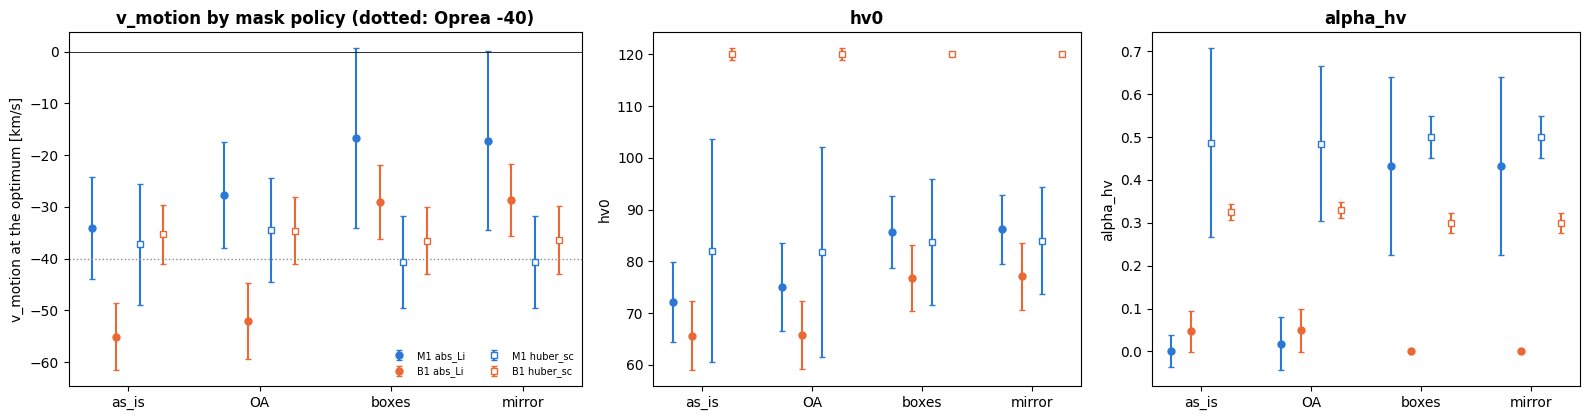

In [13]:
if RUN_POLICY_FITS:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
    xs = np.arange(len(FIT_POLICIES))
    off = {("abs_Li", "motion"): -0.27, 
    ("abs_Li", "both"): -0.09, ("huber_sc", "motion"): 0.09, ("huber_sc", "both"): 0.27}

    for (var, lab_), dx in off.items():
        if var not in FIT_VARS: 
            continue
        mm = np.array([opt_val(FIT3.get((lab_, vkey(var, p, "one"))), lab_, "v_motion") for p in FIT_POLICIES])
        axs[0].errorbar(xs + dx, mm[:, 0], yerr=mm[:, 1], fmt="o" if var == "abs_Li" else "s", 
                        ms=5, capsize=2, color=STY[lab_][1], mfc=STY[lab_][1] if var == "abs_Li" else "white", 
                        label=f"{STY[lab_][0]} {var}")
        
    axs[0].axhline(-40, color="#8d8c88", ls=":", lw=1)
    axs[0].axhline(0, color="#0b0b0b", lw=0.6)
    axs[0].set_xticks(xs)
    axs[0].set_xticklabels(FIT_POLICIES)
    axs[0].set_ylabel("v_motion at the optimum [km/s]")
    axs[0].set_title("v_motion by mask policy (dotted: Oprea -40)", weight="bold")
    axs[0].legend(frameon=False, fontsize=7, ncol=2)

    for ax, nm in ((axs[1], "hv0"), (axs[2], "alpha_hv")):
        for (var, lab_), dx in off.items():
            if var not in FIT_VARS: 
                continue
            mm = np.array([opt_val(FIT3.get((lab_, vkey(var, p, "one"))), lab_, nm) for p in FIT_POLICIES])
            ax.errorbar(xs + dx, mm[:, 0], yerr=mm[:, 1], fmt="o" if var == "abs_Li" else "s", 
                        ms=5, capsize=2, color=STY[lab_][1], mfc=STY[lab_][1] if var == "abs_Li" else "white")
            
        ax.set_xticks(xs)
        ax.set_xticklabels(FIT_POLICIES)
        ax.set_ylabel(nm)
        ax.set_title(nm, weight="bold")

    plt.tight_layout()
    plt.show()

**Reading it.**

We see that the primary shift occurs when going from `OA` to boxes, which is expected since the Magellanic System accounts for ~8% of the flux. However, the smaller changes in `v_motion` and `hv0` are encouraging. It is likely that `boxes` will be the masking policy going forward.

## 6. The north-south normalization

With one flux scale a head wind in the south lowers the southern flux and so matches LAB's weaker south. With a free ratio $\rho = s_S/s_N$, the same lowering can be bought for free, and the wind is left with the shape alone (which answers weakly). 

A prior on $\ln \rho$ sits in between: the model's Marasco-based normalization is trusted to a factor $e^{\pm\tau}$, and the wind provides the rest. In section 3, the family $\rho = e^{\lambda}$ conserves the total flux. $\lambda = 0$ is the one-scale convention.

For `huber_sc`, the residual is $-\ln L$ of independent voxels (Gaussian core), so a tempered voxel likelihood is $T R$ with $T = N_{\rm eff}/N$ and a prior $\lambda \sim N(0, \tau^2)$ adds $\lambda^2/(2\tau^2)$. The *penalised residual* of a model is

$$R_{\rm pen}(\theta, v) = \min_\lambda \left[ R(\lambda) + \frac{\lambda^2}{2 \tau^2 T} \right],$$

and a surface is fitted to it exactly as to any other residual. $\tau \to 0$ is the one-scale fit, $\tau \to \infty$ the free ratio (a profile over $\rho$; a posterior would marginalize instead). How many km/s of wind $\tau$ corresponds to is set by the slope $d \ln (M_S/M_N)/dm$ (measured below from `PR2`).

In [14]:
# The slope of the model's north/south flux ratio with the wind, from the PR2 places (m = (h_N - h_S)/2, c = (h_N + h_S)/2).
SLOPE_M = 0.0212
SLOPE_SRC = "default from the earlier notebook (PR2 not available here)"

if pack2 is not None:
    E2 = eval_stage("PR2", POLICY0, list(NIDX["PR2"]), tables=False)
    rows = []
    for p, ns in REP2.items():
        if p in ("dec_opt",) or p not in WIND: continue
        hN, hS = WIND[p]
        lr = np.mean([np.log(E2[n]["M_S"] / E2[n]["M_N"]) for n in ns if n in E2])
        rows.append((1.0, 0.5 * (hN - hS), 0.5 * (hN + hS), lr))

    A = np.array(rows)
    coef, *_ = np.linalg.lstsq(A[:, :3], A[:, 3], rcond=None)
    rms = np.sqrt(np.mean((A[:, :3] @ coef - A[:, 3]) ** 2))
    SLOPE_M = float(coef[1])
    SLOPE_SRC = f"PR2 places, policy {POLICY0}: ln(M_S/M_N) = {coef[0]:.3f} + {coef[1]:.4f} m + {coef[2]:.4f} c (rms {rms:.3f})"

print("Slope of ln(M_S/M_N) with the wind m:", SLOPE_SRC)
print(f"> a change of {SLOPE_M * 10:.2f} in ln(rho) is worth 10 km/s of m."
      f"> tau = 0.1 / 0.25 / 0.5 corresponds to {0.1/abs(SLOPE_M):.0f} / {0.25/abs(SLOPE_M):.0f} / {0.5/abs(SLOPE_M):.0f} km/s")
T0 = T_of(POLICY0)
print(f"> tempering T = N_eff / N = {N_EFF:.0f} / {N_EFF / T0:.0f} = 1/{1 / T0:.0f}")

Slope of ln(M_S/M_N) with the wind m: PR2 places, policy OA: ln(M_S/M_N) = -0.172 + 0.0201 m + 0.0032 c (rms 0.037)
> a change of 0.20 in ln(rho) is worth 10 km/s of m.> tau = 0.1 / 0.25 / 0.5 corresponds to 5 / 12 / 25 km/s
> tempering T = N_eff / N = 250 / 156998 = 1/628


Policy OA; huber_sc at the representative model of each stage: lambda = ln(s_S/s_N)
stage   lambda_hat (own scale)  lambda of min R   T [R(0) - R(min)]  T [R(hat) - R(min)]
G1                      -0.410           -0.405                1.00                 0.00   model P1_opt_abs_Li_s5
M1                       0.305            0.335                0.57                 0.01   model PM1_opt_abs_Li_s7
B1                       0.422            0.465                1.08                 0.01   model PB1_opt_abs_Li_s0


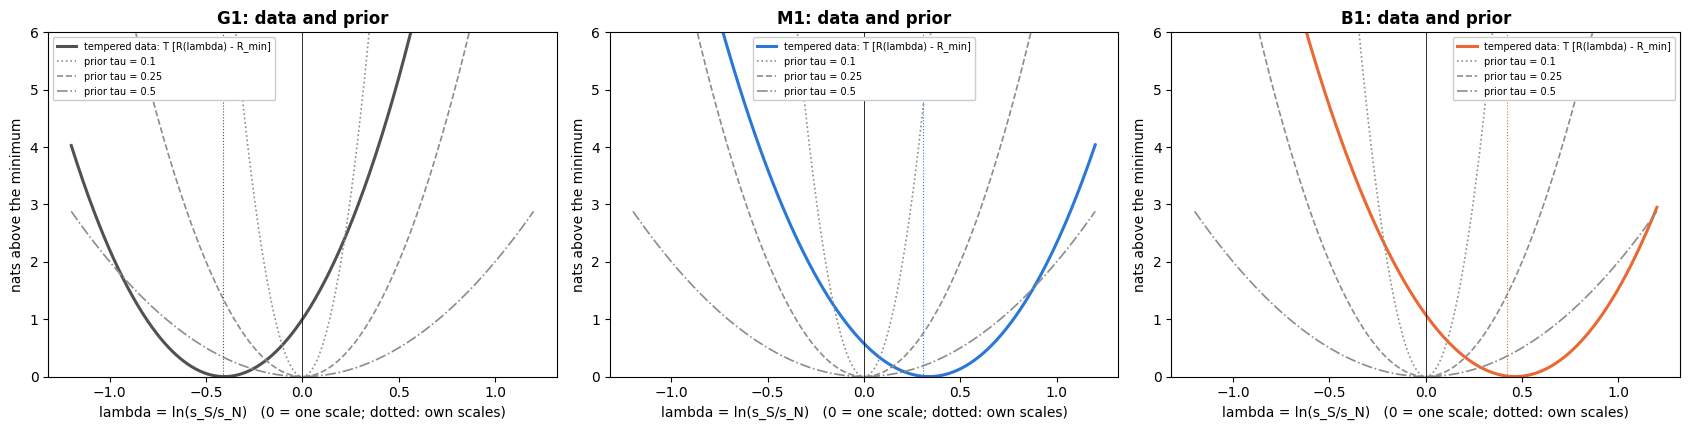


Where the sum of the tempered data curve and the prior has its minimum (lambda*), at the same model,
for the tempering T0 x (0.1, 0.3, 1, 3, 10):
stage    tau  T0 x 0.1  T0 x 0.3    T0 x 1    T0 x 3   T0 x 10
G1      0.10     -0.00     -0.01     -0.04     -0.11     -0.22
G1      0.25     -0.03     -0.07     -0.18     -0.28     -0.36
G1      0.50     -0.09     -0.19     -0.30     -0.36     -0.39
M1      0.10      0.01      0.01      0.03      0.08      0.17
M1      0.25      0.02      0.06      0.13      0.22      0.29
M1      0.50      0.07      0.15      0.24      0.30      0.33
B1      0.10      0.01      0.02      0.04      0.10      0.23
B1      0.25      0.03      0.08      0.18      0.31      0.40
B1      0.50      0.09      0.20      0.33      0.41      0.45


In [15]:
# R_huber(lambda) in tempered nats at the representative model (the median replicate at each stage's abs_Li optimum), with the prior penalty of a few tau
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
LAMF = np.linspace(LAM[0], LAM[-1], 481)
print(f"Policy {POLICY0}; huber_sc at the representative model of each stage: lambda = ln(s_S/s_N)")
print(f"{'stage':6s} {'lambda_hat (own scale)':>23s} {'lambda of min R':>16s} "
      f"{'T [R(0) - R(min)]':>19s} {'T [R(hat) - R(min)]':>20s}")

for ax, lab_ in zip(axs, LABELS):
    nm = best_model(lab_)
    r = EV[(lab_, POLICY0)][nm]
    RT = r["tab_huber_sc"].sum(1)
    RF = CubicSpline(LAM, RT)(LAMF)

    lhat = np.log((r["D_S"] / r["D_N"]) / (r["M_S"] / r["M_N"]))
    lmin = LAMF[RF.argmin()]

    print(f"{STY[lab_][0]:6s} {lhat:23.3f} {lmin:16.3f} {T0 * (CubicSpline(LAM, RT)(0.0) - RF.min()):19.2f} "
          f"{T0 * (CubicSpline(LAM, RT)(lhat) - RF.min()):20.2f}   model {nm}")
    
    ax.plot(LAMF, T0 * (RF - RF.min()), "-", color=STY[lab_][1], lw=2.2, label="tempered data: T [R(lambda) - R_min]")
    for tau, ls in zip((0.1, 0.25, 0.5), (":", "--", "-.")): 
        ax.plot(LAMF, LAMF ** 2 / (2 * tau ** 2), ls, color="#8d8c88", lw=1.2, label=f"prior tau = {tau:g}")

    ax.axvline(0.0, color="#0b0b0b", lw=0.6)
    ax.axvline(lhat, color=STY[lab_][1], lw=0.8, ls=":")
    ax.set(xlabel="lambda = ln(s_S/s_N)   (0 = one scale; dotted: own scales)", ylabel="nats above the minimum", ylim=(0, 6))
    ax.set_title(f"{STY[lab_][0]}: data and prior", weight="bold")
    ax.legend(framealpha=1, fontsize=7)
plt.tight_layout()
plt.show()

print("\nWhere the sum of the tempered data curve and the prior has its minimum (lambda*), at the same model,\n"
      "for the tempering T0 x (0.1, 0.3, 1, 3, 10):")
print(f"{'stage':6s} {'tau':>5s} " + " ".join(f"{'T0 x %g' % f:>9s}" for f in (0.1, 0.3, 1, 3, 10)))
for lab_ in LABELS:
    nm = best_model(lab_)
    RT = EV[(lab_, POLICY0)][nm]["tab_huber_sc"].sum(1)
    RF = CubicSpline(LAM, RT)(LAMF)
    for tau in (0.1, 0.25, 0.5): 
        print(f"{STY[lab_][0]:6s} {tau:5.2f} " + \
               " ".join(f"{LAMF[(f * T0 * RF + LAMF ** 2 / (2 * tau ** 2)).argmin()]:9.2f}" for f in (0.1, 0.3, 1, 3, 10)))

### 6.1 The refit under each treatment of the normalization

`huber_sc` under `POLICY0` with: one scale ($\tau \to 0$), an informative prior ($\tau$ = 0.1, 0.25, 0.5), and a free ratio; and `abs_Li` (no nats, hence no prior) with one scale, own scales and a free ratio. The last column of the first table is the median $\rho^* = e^{\lambda^*}$ over the ten best models of each variant: how far from 1 the normalization went. A surface per variant and stage, cached.

In [16]:
RUN_NORM_FITS = True
NORM_SPECS = [("huber_sc", "one", None)] + [("huber_sc", "tau", t) for t in (0.1, 0.25, 0.5)] + [("huber_sc", "free", None)] \
           + [("abs_Li", "one", None), ("abs_Li", "own", None), ("abs_Li", "free", None)]

if RUN_NORM_FITS:
    for lab_ in FIT_STAGES:
        for var, norm, tau in NORM_SPECS: fit_variant(lab_, var, POLICY0, norm, tau)
    for lab_ in FIT_STAGES:
        entries = [(f"{var} {norm}{'' if tau is None else ' ' + \
                                   format(tau, 'g')}", lab_, vkey(var, POLICY0, norm, tau)) for var, norm, tau in NORM_SPECS]
        print_fits(entries, title=f"\n{STY[lab_][0]} | policy {POLICY0}: optimum under each treatment of the normalization")

    print("\nmedian rho* = s_S/s_N over the 10 best models of each variant (huber_sc, penalised / profiled):")
    for lab_ in FIT_STAGES:
        row = f"  {STY[lab_][0]}: "
        for var, norm, tau in NORM_SPECS:
            if var != "huber_sc" or norm == "one": 
                continue
            R_, L_ = pen_values(EV[(lab_, POLICY0)], var, norm, tau, T0)
            nm = sorted((n for n in grid_names(lab_) if n in R_), key=R_.get)[:10]
            row += f"{norm}{'' if tau is None else format(tau, 'g')}: {np.exp(np.median([L_[n] for n in nm])):.2f}   "
        print(row)


M1 | policy OA: optimum under each treatment of the normalization
                                               hv0     alpha_conds        alpha_hv           f_ion        v_motion
huber_sc one                         81.79 ±20.27    4.60 ± 1.71    0.48 ± 0.18    0.00 ± 0.03  -34.41 ±10.03
huber_sc tau 0.1                     81.07 ±20.38    4.53 ± 1.71    0.49 ± 0.18    0.00 ± 0.03  -34.97 ±10.88
huber_sc tau 0.25                    79.85 ±20.62    4.53 ± 1.83    0.50 ± 0.19    0.00 ± 0.03  -35.70 ±10.15
huber_sc tau 0.5                     79.44 ±21.87    4.27 ± 1.95    0.50 ± 0.20    0.00 ± 0.03  -36.33 ±10.88
huber_sc free                        79.17 ±20.53    4.17 ± 1.98    0.50 ± 0.20    0.00 ± 0.03  -37.37 ±10.88
abs_Li one                           75.04 ± 8.58    9.47 ± 1.20    0.02 ± 0.06    0.00 ± 0.02  -27.68 ±10.29
abs_Li own                           75.06 ± 7.72    6.46 ± 1.95    0.29 ± 0.17    0.01 ± 0.05   16.54 ±19.54
abs_Li free                          74.13 ± 9.1

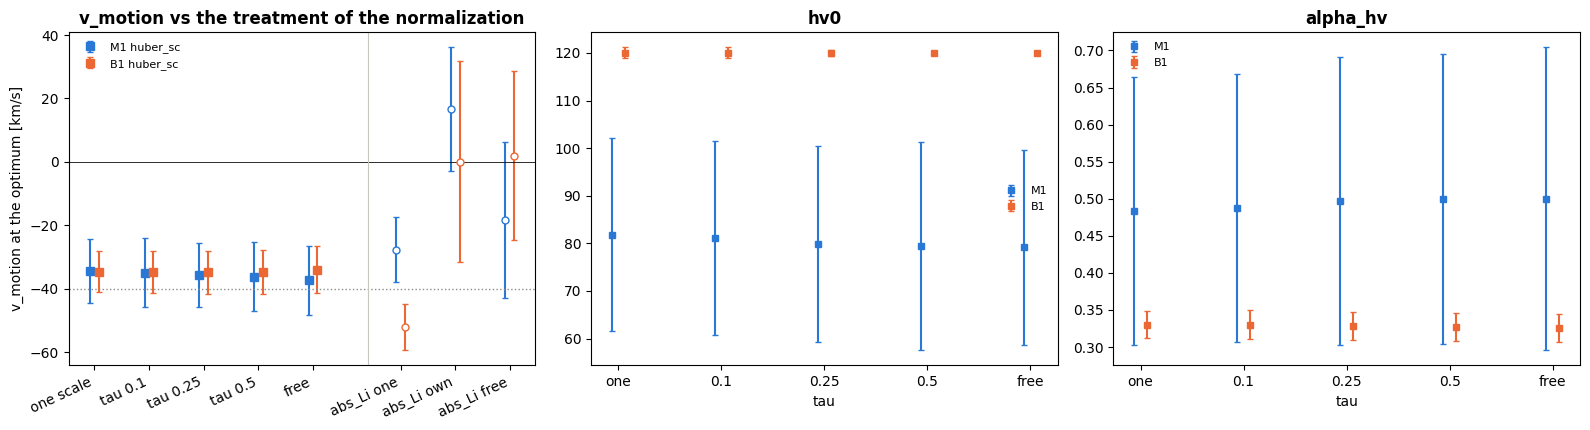

In [17]:
if RUN_NORM_FITS:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
    xs = np.arange(5)
    for lab_, dx in (("motion", -0.08), ("both", 0.08)):
        mm = np.array([opt_val(FIT3.get((lab_, vkey("huber_sc", POLICY0, nm_, t_))), lab_, "v_motion") for nm_, t_ in (
                        ("one", None), ("tau", 0.1), ("tau", 0.25), ("tau", 0.5), ("free", None))])
        
        axs[0].errorbar(xs + dx, mm[:, 0], yerr=mm[:, 1], fmt="s", ms=6, capsize=2, 
                        color=STY[lab_][1], label=f"{STY[lab_][0]} huber_sc")
        
        for j, nm_ in enumerate(("one", "own", "free")):
            o = opt_val(FIT3.get((lab_, vkey("abs_Li", POLICY0, nm_))), lab_, "v_motion")
            axs[0].errorbar([5.6 + j + dx], [o[0]], yerr=[o[1]], fmt="o", ms=5, capsize=2, color=STY[lab_][1], mfc="white")

    axs[0].set_xticks(list(xs) + [5.6, 6.6, 7.6])
    axs[0].set_xticklabels(["one scale", "tau 0.1", "tau 0.25", "tau 0.5", "free", "abs_Li one", "abs_Li own", "abs_Li free"], 
                           rotation=25, ha="right")
    
    axs[0].axhline(-40, color="#8d8c88", ls=":", lw=1)
    axs[0].axhline(0, color="#0b0b0b", lw=0.6)
    axs[0].axvline(5.0, color="#c7c6c0", lw=0.8)
    axs[0].set(ylabel="v_motion at the optimum [km/s]")
    axs[0].set_title("v_motion vs the treatment of the normalization", weight="bold")
    axs[0].legend(frameon=False, fontsize=8)

    for ax, nm in ((axs[1], "hv0"), (axs[2], "alpha_hv")):
        for lab_, dx in (("motion", -0.06), ("both", 0.06)):
            mm = np.array([opt_val(FIT3.get((lab_, vkey("huber_sc", POLICY0, nm_, t_))), lab_, nm) for nm_, t_ in (
                ("one", None), ("tau", 0.1), ("tau", 0.25), ("tau", 0.5), ("free", None))])
            ax.errorbar(xs + dx, mm[:, 0], yerr=mm[:, 1], fmt="s", ms=5, capsize=2, color=STY[lab_][1], label=STY[lab_][0])
        
        ax.set_xticks(xs)
        ax.set_xticklabels(["one", "0.1", "0.25", "0.5", "free"])
        ax.set_xlabel("tau")
        ax.set_title(nm, weight="bold")
        ax.legend(frameon=False, fontsize=8)

    plt.tight_layout()
    plt.show()

**Reading it.** 

We see that the choice of a prior effects variables like `huber_sc` negligibly, going from one scale to separate hemisphere scales is worth only about 1 tempered nat, against about 6 for the wind. Although `huber_sc` has other problems in `hv0`, it shows us that it is a reliable parameter for the $v_{\rm motion}$ search. `abs_Li`, on the other hand, has a clear dependency on the prior choice: its wind is essentially the amplitude ratio, and it goes to +17 ± 20 with own scales.

## 7. The likelihood

Two questions for `huber_sc`, the candidate of my choice, with the runner-up being `abs_sc`, from the previous notebook. 

**(a)** Its three hyper-parameters are assumed: $\sigma_0 = 12$ mK is four times the LAB noise, $\epsilon = 1$ comes from the rms scatter of the residual (the robust spread is three times smaller), $k = 1.5$ is conventional. About 71 % of its weight sits at $M < 0.02$ K, where $\sigma_0$ decides how much a voxel counts. How much do the optima (in particular $v_{\rm motion}$) move when each is changed? 

**(b)** A voxel likelihood tempered by $N_{\rm eff}/N$ against a Huber on *blocks* of $4 \times 4 \times 4$ cells (16° x 16° x 32 km/s, about the correlation lengths): where do the two put the wind, and how many nats is the wind worth under each?

The scan changes one hyper-parameter at a time around $(12 \text{ mK}, 1, 1.5)$; $k = 100$ is the Gaussian limit. One flux scale, `POLICY0`. `M1` is fitted for every setting (`G1` and `B1` enter through the noise unit and the best-10 gain).

In [18]:
RUN_SCAN = True
SCAN = {"sigma0": [0.006, 0.009, 0.012, 0.018, 0.024], "eps": [0.3, 0.5, 1.0, 1.5, 2.5], "k": [1.0, 1.5, 2.5, 5.0, 100.0]}
COMBOS = []

for nm_, vals_ in SCAN.items():
    for x in vals_:
        hp_ = {"sigma0": (x, EPS, HUBER_K), "eps": (SIG0, x, HUBER_K), "k": (SIG0, EPS, x)}[nm_]
        if hp_ not in COMBOS: 
            COMBOS.append(hp_)

def ckey(hp_): return f"hub[s{hp_[0] * 1e3:g},e{hp_[1]:g},k{hp_[2]:g}]@{POLICY0}@one"

def scan_stage(label, hps, names, policy=POLICY0):
    """ huber_sc, one flux scale, for several hyper-parameter sets: {name: array(len(hps))}; cached. """
    f = DIAG / f"v3scan_{label}_{policy}_{hashlib.sha1(repr(hps).encode()).hexdigest()[:8]}_{TAG}.pkl"
    res = pickle.load(open(f, "rb")) if f.exists() else {}
    todo = [n for n in names if n not in res]
    if todo:
        MAT, idx = MV[label], NIDX[label]
        def fn(n):
            m = np.asarray(MAT[idx[n]], dtype=np.float64)
            ok = keep_vec(m, policy, DATA)
            o, m, w = DATA[ok], m[ok], WGT[ok]
            s1 = (w * o).sum() / (w * m).sum()
            return np.array([hub(o, s1 * m, w, *hp_).sum() for hp_ in hps])
        
        t0 = time.time()
        res.update(pmap(fn, todo))
        pickle.dump(res, open(f, "wb"))
        print(f"> {label}: {len(todo)} models x {len(hps)} settings in {time.time() - t0:.0f} s")
    return {n: res[n] for n in names}

SCANV = {}
if RUN_SCAN:
    for lab_ in LABELS:
        r_ = scan_stage(lab_, COMBOS, grid_names(lab_) + rep_names(lab_))
        for j, hp_ in enumerate(COMBOS): 
            SCANV.setdefault(hp_, {})[lab_] = {n: float(v[j]) for n, v in r_.items()}

    for hp_ in COMBOS: 
        register(ckey(hp_), SCANV[hp_])

In [19]:
# Where does each setting look: the share of its terms at the representative G1 model, and the fits?
def weight_shares(hp_, label="G1"):
    nm = best_model(label)
    m = np.asarray(MV[label][NIDX[label][nm]], dtype=np.float64)
    ok = keep_vec(m, POLICY0, DATA)
    o, m, w = DATA[ok], m[ok], WGT[ok]

    s1 = (w * o).sum() / (w * m).sum()
    t = hub(o, s1 * m, w, *hp_); ms = s1 * m
    bb = np.abs(bgrid[ib][ok])
    return 100 * t[ms < 0.02].sum() / t.sum(), 100 * t[bb < 15].sum() / t.sum(), 100 * t[NORTH[ok]].sum() / t.sum()

SCANFIT = {}
if RUN_SCAN:
    for hp_ in COMBOS: SCANFIT[hp_] = fit_vals("motion", ckey(hp_), SCANV[hp_])
    print(f"\nM1, policy {POLICY0}, one flux scale: optimum for each setting (changed hyper-parameter in capitals)")
    print(f"{'sigma0 [mK]':>11s} {'eps':>5s} {'k':>5s} | {'hv_pivot':>14s} {'alpha_conds':>14s} "
          f"{'alpha_hv':>14s} {'v_motion':>14s} | {'M<0.02 K':>9s} {'|b|<15':>7s} {'north':>6s} | "
          f"{'M1 over G1':>11s} {'[u]':>6s}")
    
    for hp_ in COMBOS:
        o = SCANFIT[hp_]; wsh = weight_shares(hp_); u = NOISE_V3[ckey(hp_)][40]
        b10 = np.sort([SCANV[hp_]["motion"][n] for n in grid_names("motion")])[:10].mean()
        a10 = np.sort([SCANV[hp_]["G1"][n] for n in grid_names("G1")])[:10].mean()
        mark = "   <- default" if hp_ == HP else ""

        print(f"{hp_[0] * 1e3:11g} {hp_[1]:5g} {hp_[2]:5g} | " + \
              " ".join(cellv(o, "motion", c) for c in ("hv_pivot", "alpha_conds", "alpha_hv", "v_motion")) + \
                  f" | {wsh[0]:9.1f} {wsh[1]:7.1f} {wsh[2]:6.1f} | {100 * (b10 / a10 - 1):+10.2f}% " + \
                  f"{np.log(b10 / a10) / u:+6.1f}{mark}")


M1, policy OA, one flux scale: optimum for each setting (changed hyper-parameter in capitals)
sigma0 [mK]   eps     k |       hv_pivot    alpha_conds       alpha_hv       v_motion |  M<0.02 K  |b|<15  north |  M1 over G1    [u]
          6     1   1.5 |  124.79 ±10.76    2.11 ± 1.09    0.50 ± 0.03  -39.67 ± 8.92 |      85.2    41.8   53.2 |      +0.11%   +0.0
          9     1   1.5 |  116.75 ± 8.01    3.16 ± 1.07    0.50 ± 0.05  -37.72 ± 8.99 |      77.4    42.5   55.6 |      +1.04%   +0.3
         12     1   1.5 |  112.31 ± 9.74    4.60 ± 1.71    0.48 ± 0.18  -34.41 ±10.03 |      70.1    42.2   57.7 |      +0.92%   +0.3   <- default
         18     1   1.5 |  122.71 ± 8.94    8.76 ± 1.32    0.09 ± 0.09  -30.29 ±10.14 |      58.0    40.3   60.6 |      -0.68%   -0.2
         24     1   1.5 |  111.25 ± 8.74    9.82 ± 0.81    0.09 ± 0.11  -25.49 ±12.37 |      49.0    38.2   62.7 |      -0.98%   -0.4
         12   0.3   1.5 |   92.61 ± 9.28    7.23 ± 1.76    0.46 ± 0.21  -27.28 ±15.84 | 

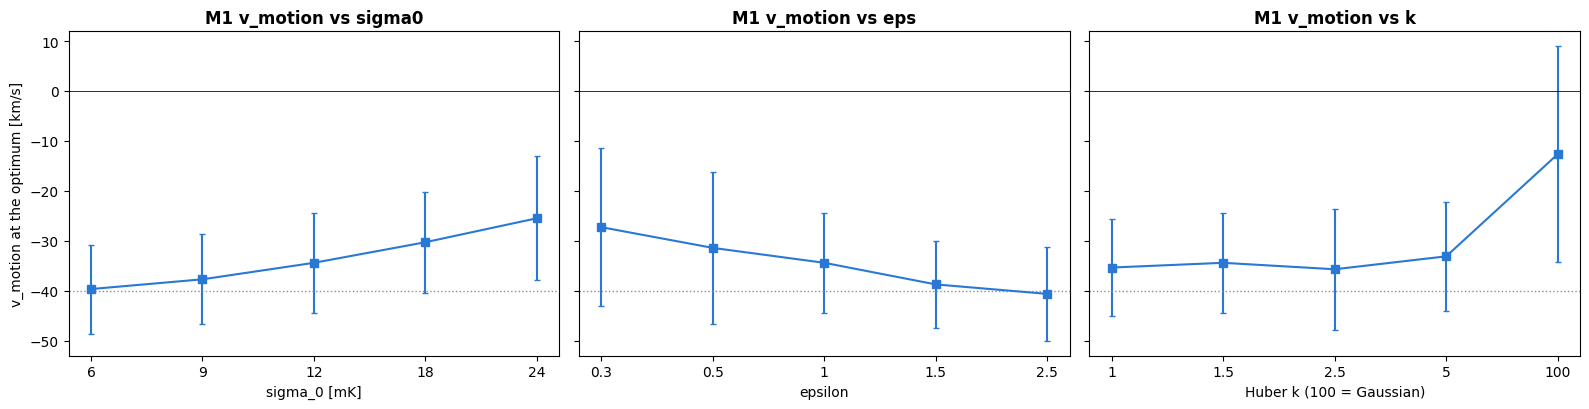

In [20]:
if RUN_SCAN:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
    for ax, (nm_, xs_) in zip(axs, SCAN.items()):
        hps = [{"sigma0": (x, EPS, HUBER_K), "eps": (SIG0, x, HUBER_K), "k": (SIG0, EPS, x)}[nm_] for x in xs_]
        mm = np.array([opt_val(SCANFIT[h], "motion", "v_motion") for h in hps])
        ax.errorbar(range(len(xs_)), mm[:, 0], yerr=mm[:, 1], fmt="s-", ms=6, capsize=2, color="#2a78d6")
        
        ax.set_xticks(range(len(xs_)))
        ax.set_xticklabels([f"{x * 1e3:g}" if nm_ == "sigma0" else f"{x:g}" for x in xs_])
        ax.axhline(-40, color="#8d8c88", ls=":", lw=1)
        ax.axhline(0, color="#0b0b0b", lw=0.6)
        ax.set_xlabel({"sigma0": "sigma_0 [mK]", "eps": "epsilon", "k": "Huber k (100 = Gaussian)"}[nm_])
        ax.set_title(f"M1 v_motion vs {nm_}", weight="bold")
    axs[0].set_ylabel("v_motion at the optimum [km/s]")
    
    plt.tight_layout()
    plt.show()

M1, policy OA                       v at min |  dnats at +20   dnats at +0  dnats at -20  dnats at -40  dnats at -60 |   range with dnats < 0.5
voxel Huber, one scale                 -34.0 |          9.61          5.79          1.76          0.75         18.01 |      -38 ...  -28 km/s
voxel Huber, prior tau 0.25            -32.0 |          9.51          5.82          1.53          0.89         17.61 |      -38 ...  -26 km/s
voxel Huber, free ratio                -34.0 |          9.42          6.50          2.10          0.37         13.50 |      -40 ...  -30 km/s


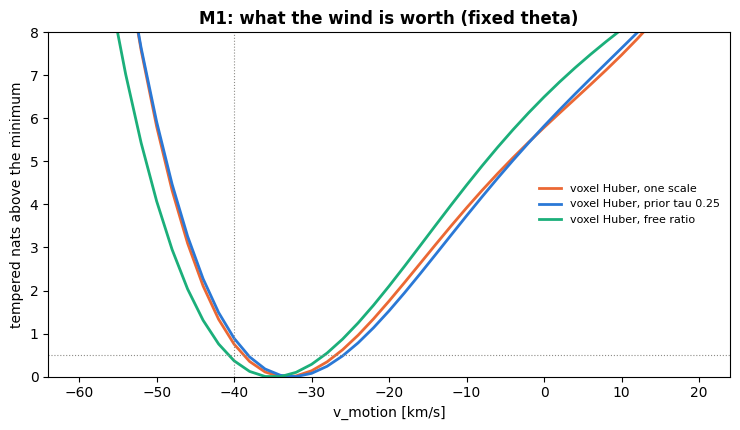

In [21]:
# The profile along v_motion at the fixed theta of each variant's optimum, in tempered nats.
def gp_mean(gp, X, chunk=4000):
    f = gp.fac; out = np.empty(len(X))
    for i in range(0, len(X), chunk):
        Z = X[i:i + chunk]; out[i:i + chunk] = g._basis(Z) @ f["beta"] + g._matern52(gp.X, Z, f["ls"], f["sf2"]).T @ f["Ki_r"]
    return out

VG = np.arange(V_MOTION_RANGE[0], V_MOTION_RANGE[1] + 1e-9, 2.0)
def v_profile(label, key, T):
    """ Tempered nats along v_motion at the theta of the optimum of the fit (key, label): T [R(v) - R_min.] """
    o = FIT3[(label, key)]
    th = np.asarray(o["est"]["theta_mean_opt"], float)[:4]
    X = np.c_[np.tile(th, (len(VG), 1)), VG]
    y = gp_mean(o["gp"], feat(X))
    R = np.exp(-o["data"]["s_ref"] * y)
    return T * (R - R.min()), VG[R.argmin()]

PROF = {}
SPEC6 = [("voxel Huber, one scale", vkey("huber_sc", POLICY0, "one"), T0), 
         ("voxel Huber, prior tau 0.25", vkey("huber_sc", POLICY0, "tau", 0.25), T0),
         ("voxel Huber, free ratio", vkey("huber_sc", POLICY0, "free"), T0)]

print(f"{'M1, policy ' + POLICY0:34s} {'v at min':>9s} | " + \
      " ".join(f"{'dnats at %+d' % v:>13s}" for v in (20, 0, -20, -40, -60)) + f" | {'range with dnats < 0.5':>24s}")

for cap, key, T in SPEC6:
    if ("motion", key) not in FIT3: continue
    nats, vmin = v_profile("motion", key, T)
    PROF[cap] = (nats, vmin)
    inside = VG[nats <= 0.5]
    print(f"{cap:34s} {vmin:+9.1f} | " + \
          " ".join(f"{nats[np.argmin(np.abs(VG - v))]:13.2f}" for v in (20, 0, -20, -40, -60)) + \
            f" | {inside.min():+8.0f} ... {inside.max():+4.0f} km/s")
    
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for (cap, (nats, vmin)), col in zip(PROF.items(), ("#eb6834", "#2a78d6", "#1baf7a")): 
    ax.plot(VG, nats, "-", color=col, lw=2, label=cap)
ax.axhline(0.5, color="#8d8c88", lw=0.8, ls=":")
ax.axvline(-40, color="#8d8c88", lw=0.8, ls=":")
ax.set(xlabel="v_motion [km/s]", ylabel="tempered nats above the minimum", ylim=(0, 8))
ax.set_title("M1: what the wind is worth (fixed theta)", weight="bold")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 8. The surrogate

The surface is a GP fitted to $y = -\ln R/u$ with a per-point noise $u_i/u$ and two fitted nuisance terms (`noise_scale`, `extra_noise`). 

The earlier notebooks found the run noise to be heavy-tailed (about 1 % of the models are 20-70 % off the surface, upward) and heteroscedastic (the outliers grow with $\alpha_{\rm hv}$), and the optimum to sit on one of two near-degenerate modes: L ($hv_{\rm pivot} \approx 70$, $\alpha_{\rm hv} \approx 0$, $\alpha_{\rm conds}$ 7-9) or H ($hv_{\rm pivot}$ 100-150, $\alpha_{\rm hv}$ 0.3-0.5), decided by about seven models. 

For the Bayesian step, the surrogate must not be able to do that. Three things here: 
* the leave-one-out residuals of the stage fits by $\alpha_{\rm hv}$ (and the noise of the replicate places by their $\alpha_{\rm hv}$); 
* a robust refit (iteratively reweighted: the noise of a point is inflated by the Student-$t$ ($\nu = 3$) weight $(\nu + z^2)/(\nu + 1)$ of its leave-one-out residual $z$, so a point that the others do not predict stops pulling the surface); and 
* the share of the optimum draws on each mode, plain against robust.

In [22]:
from scipy.stats import spearmanr
Z_VARS = [("huber_sc", POLICY0, "one", None), ("abs_Li", POLICY0, "one", None)]
ZS = {}
print(f"Leave-one-out z of the stage fits (policy {POLICY0}, one scale): "
      f"share with |z| > 3 / 4, and the median |z| by alpha_hv")

print(f"{'stage':6s} {'variable':9s} {'n':>4s} {'|z|>3':>7s} {'|z|>4':>7s} | "
      f"{'alpha_hv < 0.1':>15s} {'0.1-0.25':>9s} {'> 0.25':>8s} | {'Spearman |z|, alpha_hv':>24s}")

for lab_ in LABELS:
    for var, pol, norm, tau in Z_VARS:
        key = vkey(var, pol, norm, tau)
        fit_variant(lab_, var, pol, norm, tau)
        o = FIT3[(lab_, key)]

        z = o["gp"].loo()[2]
        th = o["data"]["theta"]
        ah = th[:, 2]
        ZS[(lab_, key)] = (z, th, o["data"]["names"])

        q = [np.median(np.abs(z[m])) if m.sum() > 3 else np.nan for m in (ah < 0.1, (ah >= 0.1) & (ah < 0.25), ah >= 0.25)]
        rho = spearmanr(np.abs(z), ah)
        print(f"{STY[lab_][0]:6s} {var:9s} {len(z):4d} {100 * np.mean(np.abs(z) > 3):6.1f}% "
              f"{100 * np.mean(np.abs(z) > 4):6.1f}% | {q[0]:15.2f} {q[1]:9.2f} {q[2]:8.2f} | "
              f"{rho.correlation:+9.2f} (p = {rho.pvalue:.2g})")
        
print("\nRun noise of the replicate places (sd of ln R over >= 6 seeds, huber_sc and abs_Li, one scale) "
      "against the place's parameters:")

print(f"{'stage':6s} {'place':16s} {'n':>3s} {'hv0':>6s} {'a_conds':>8s} {'a_hv':>6s} {'v':>7s} | "
      f"{'sd huber_sc':>11s} {'sd abs_Li':>10s}")

for lab_ in LABELS:
    for p, ns in sorted(STG[lab_]["REP"].items()):
        ns = [n for n in ns if n in EV[(lab_, POLICY0)]]
        if len(ns) < 6: 
            continue
        kw = STG[lab_]["RUNS"][ns[0]]["kw"]
        sd = [np.std(np.log([EV[(lab_, POLICY0)][n][f"{v}|one"] for n in ns]), ddof=1) for v in ("huber_sc", "abs_Li")]
        print(f"{STY[lab_][0]:6s} {p:16s} {len(ns):3d} {kw.get('hv0', np.nan):6.1f} "
              f"{kw.get('alpha_conds', np.nan):8.2f} {kw.get('alpha_hv', np.nan):6.2f} {kw.get('v_motion', 0.0):7.1f} "
              f"| {100 * sd[0]:10.2f}% {100 * sd[1]:9.2f}%")

Leave-one-out z of the stage fits (policy OA, one scale): share with |z| > 3 / 4, and the median |z| by alpha_hv
stage  variable     n   |z|>3   |z|>4 |  alpha_hv < 0.1  0.1-0.25   > 0.25 |   Spearman |z|, alpha_hv
G1     huber_sc   512    1.4%    0.4% |            0.66      0.69     0.45 |     -0.16 (p = 0.00033)
G1     abs_Li     512    0.6%    0.6% |            0.59      0.50     0.46 |     -0.10 (p = 0.026)
M1     huber_sc   512    1.8%    1.4% |            0.25      0.23     0.35 |     +0.20 (p = 3.1e-06)
M1     abs_Li     512    1.8%    1.2% |            0.23      0.25     0.38 |     +0.27 (p = 2.8e-10)
B1     huber_sc   512    1.6%    0.8% |            0.52      0.51     0.50 |     -0.02 (p = 0.63)
B1     abs_Li     512    1.2%    0.8% |            0.42      0.40     0.42 |     +0.10 (p = 0.024)

Run noise of the replicate places (sd of ln R over >= 6 seeds, huber_sc and abs_Li, one scale) against the place's parameters:
stage  place              n    hv0  a_conds   a_hv       v

In [23]:
NU_T = 3.0
def robust_fit(label, key, vals, iters=4, n_draws=200, n_restarts=4):
    """ 
    GP fit with Student-t (nu = 3) reweighting by IRLS: 
    sd_i = sd0_i sqrt((nu + z_i^2) / (nu + 1)), z the leave-one-out residual against the BASE noise. 
    """
    names = [n for n in grid_names(label) if n in vals[label]]
    bx, ft = BOXF[label]

    res_ = {n: {"keys": [key], "R_" + key: vals[label][n]} for n in names}
    runs_ = {n: STG[label]["RUNS"][n] for n in names}

    sig = hashlib.sha1(json.dumps([sorted(names), round(sum(res_[n]["R_" + key] for n in names), 6), 
                                   NOISE_V3[key], iters, NU_T], default=str).encode()).hexdigest()
    
    f = DIAG / f"v3rob_{label}_{key}_{V3TAG}.pkl"

    if f.exists():
        b = pickle.load(open(f, "rb"))
        if b["sig"] == sig:
            return b["out"]
        
    data = gr.collect_resid(res_, runs_, key, NOISE_V3, names=bx.names)
    X = ft(data["theta"])
    sd0 = data["sd"]
    sd = sd0.copy()

    # Hyper-parameters from the plain fit, the reweighting steps keep them.
    gp = g.GP(X, data["y"], sd0).fit(n_restarts=n_restarts, seed=1)
    for it in range(iters + 1):
        lm, ls, _ = gp.loo()
        tot = ls ** 2 + (gp.fac["scale"] * sd0) ** 2 + gp.fac["extra2"]
        z0 = (data["y"] - lm) / np.sqrt(tot)
        sd = sd0 * np.sqrt((NU_T + z0 ** 2) / (NU_T + 1.0))

        # The last step re-optimises the hyper-parameters.
        gp = gp.refit_values(data["y"], sd) if it < iters else g.GP(X, data["y"], sd).fit(n_restarts=n_restarts, seed=1)

    est = g.optimum_distribution(gp, ft, bx, n_draws=n_draws)
    out = dict(gp=gp, est=est, data=data, z0=z0, infl=sd / sd0)
    pickle.dump({"sig": sig, "out": out}, open(f, "wb"))
    return out

def mode_share(est, feat_):
    s = est["samples"]
    ah = s[:, 2]
    return 100 * np.mean(ah < 0.15)

RUN_ROBUST = True; ROB = {}
if RUN_ROBUST:
    for var in ("huber_sc", "abs_Li"):
        key, vals = get_variant(var, POLICY0, "one")
        for lab_ in LABELS:
            t0 = time.time()
            ROB[(lab_, var)] = robust_fit(lab_, key, vals)
            r = ROB[(lab_, var)]
            print(f"> robust fit {STY[lab_][0]} {var}: {np.sum(r['infl'] > 2)} of {len(r['infl'])} "
                  f"points with noise inflated by more than 2 ({time.time() - t0:.0f} s)")
            
    for var in ("huber_sc", "abs_Li"):
        print(f"\n{var}, policy {POLICY0}, one scale: plain against robust (Student-t, nu = {NU_T:g}) surface; "
              f"last column: share of the optimum draws with alpha_hv < 0.15 (mode L)")
        print(f"{'':16s} " + " ".join(f"{c:>15s}" for c in COLS5) + f" | {'mode L share':>12s}")
        
        for lab_ in LABELS:
            key = vkey(var, POLICY0, "one")
            for cap, o in (("plain", FIT3[(lab_, key)]), ("robust", ROB[(lab_, var)])):
                print(f"{STY[lab_][0] + ' ' + cap:16s} " + " ".join(cellv(o, lab_, c) for c in COLS5) + \
                      f" | {mode_share(o['est'], None):11.0f}%")

> robust fit G1 huber_sc: 3 of 512 points with noise inflated by more than 2 (0 s)
> robust fit M1 huber_sc: 4 of 512 points with noise inflated by more than 2 (0 s)
> robust fit B1 huber_sc: 3 of 512 points with noise inflated by more than 2 (0 s)
> robust fit G1 abs_Li: 3 of 512 points with noise inflated by more than 2 (0 s)
> robust fit M1 abs_Li: 8 of 512 points with noise inflated by more than 2 (0 s)
> robust fit B1 abs_Li: 4 of 512 points with noise inflated by more than 2 (0 s)

huber_sc, policy OA, one scale: plain against robust (Student-t, nu = 3) surface; last column: share of the optimum draws with alpha_hv < 0.15 (mode L)
                             hv0     alpha_conds        alpha_hv           f_ion        v_motion | mode L share
G1 plain          111.37 ± 5.82    7.86 ± 1.08    0.25 ± 0.05    0.00 ± 0.00               - |           0%
G1 robust         113.09 ± 5.86    7.82 ± 0.73    0.25 ± 0.05    0.00 ± 0.00               - |           0%
M1 plain           81.79 ±2

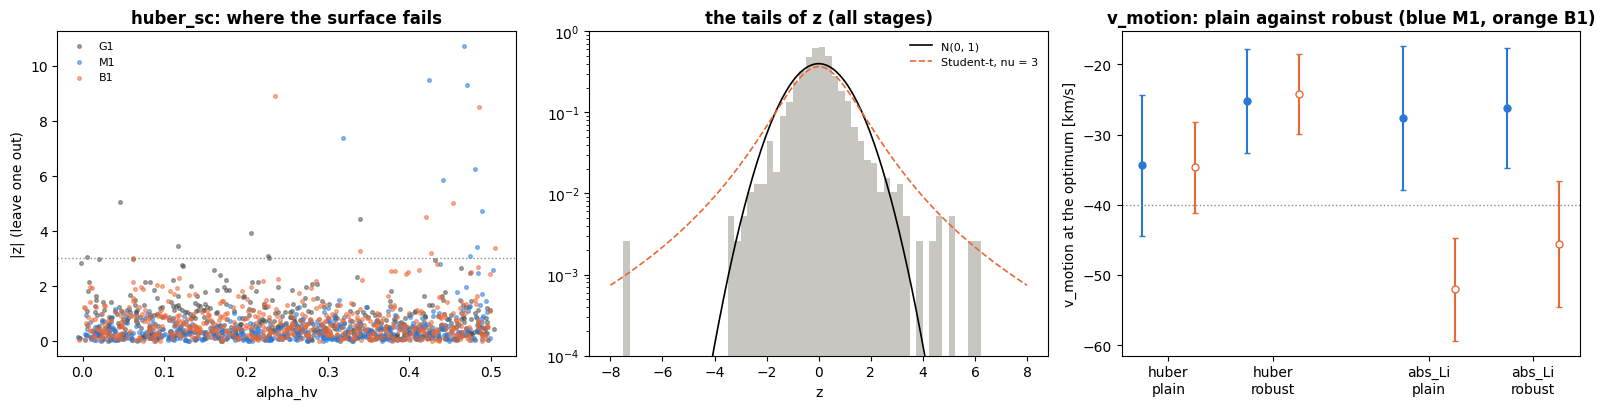

In [24]:
if RUN_ROBUST and ZS:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
    for lab_, col in (("G1", "#52514e"), ("motion", "#2a78d6"), ("both", "#eb6834")):
        z, th, _ = ZS[(lab_, vkey("huber_sc", POLICY0, "one"))]
        axs[0].scatter(th[:, 2] + np.random.default_rng(1).uniform(-0.008, 0.008, len(z)), 
                       np.abs(z), s=7, alpha=0.5, color=col, label=STY[lab_][0])
        
    axs[0].axhline(3, color="#8d8c88", ls=":", lw=1)
    axs[0].set(xlabel="alpha_hv", ylabel="|z| (leave one out)")
    axs[0].set_title("huber_sc: where the surface fails", weight="bold")
    axs[0].legend(frameon=False, fontsize=8)

    zz = np.concatenate([ZS[(l_, vkey("huber_sc", POLICY0, "one"))][0] for l_ in LABELS])
    xs_ = np.linspace(-8, 8, 200)
    
    from scipy.stats import norm as _nm, t as _t
    axs[1].hist(zz, bins=np.linspace(-8, 8, 65), density=True, color="#c7c6c0")
    axs[1].plot(xs_, _nm.pdf(xs_), "k-", lw=1.2, label="N(0, 1)")
    axs[1].plot(xs_, _t.pdf(xs_ * 1.0, 3) , "--", color="#eb6834", lw=1.2, label="Student-t, nu = 3")
    axs[1].set(xlabel="z", yscale="log", ylim=(1e-4, 1))
    axs[1].set_title("the tails of z (all stages)", weight="bold")
    axs[1].legend(frameon=False, fontsize=8)

    for lab_, dx in (("motion", -0.1), ("both", 0.1)):
        for j, var in enumerate(("huber_sc", "abs_Li")):
            if (lab_, var) not in ROB: 
                continue
            a = opt_val(FIT3[(lab_, vkey(var, POLICY0, "one"))], lab_, "v_motion")
            b = opt_val(ROB[(lab_, var)], lab_, "v_motion")
            axs[2].errorbar([j - 0.2 + dx, j + 0.2 + dx], [a[0], b[0]], yerr=[a[1], b[1]], 
                            fmt="o", ms=5, capsize=2, color=STY[lab_][1], mfc="white" if lab_ == "both" else STY[lab_][1])
            
    axs[2].set_xticks([-0.2, 0.2, 0.8, 1.2])
    axs[2].set_xticklabels(["huber\nplain", "huber\nrobust", "abs_Li\nplain", "abs_Li\nrobust"])
    axs[2].axhline(-40, color="#8d8c88", ls=":", lw=1)
    axs[2].set_ylabel("v_motion at the optimum [km/s]")
    axs[2].set_title("v_motion: plain against robust (blue M1, orange B1)", weight="bold")
    
    plt.tight_layout()
    plt.show()

**Reading it.** 

The $|z|$ table says whether the surfaces fail more where $\alpha_{\rm hv}$ is large (heteroscedastic noise: the Gaussian GP overweights a few high-$\alpha_{\rm hv}$ runs). The robust refit says whether the optimum, and in particular the L / H split and $v_{\rm motion}$, depend on a handful of runs. If plain and robust agree within the GP error, the surrogate is not the weak link. If the mode share moves to a mixture, the Bayesian step must carry a robust surrogate (or a surrogate noise that grows with $\alpha_{\rm hv}$) to avoid a posterior decided by some models.

> Looking at both `abs_Li` and `huber_sc`, we see that this depends heavily on the parameter and regardless of how much they are afflicted by the tail. We see that `huber_sc` has low mixture, but `abs_Li` has very much.

## 9. A closed loop: can the pipeline tell a wind from a mask and from a normalization?

If the sky *were* a model with a known wind, a known north-south normalization difference and a known mask artefact, with noise like LAB's, would the pipeline (variable, policy, normalization treatment, surface fit) return the wind and only the wind? We can check this by running mock simulations.

**The fake sky is built from a model run that is not in the grid:** We make a `PR2` replicate (Oprea's $(h_N, h_S) = (-40, +40)$ at the M1 optimum, or the same $\theta$ without wind). It is scaled to LAB's flux on the voxels both have, multiplied in the south by a factor, and given noise of three kinds:
* a **multiplicative clumpy** field ( heavy-tailed patches: each block of cells draws its amplitude from a Student-$t$, $\nu = 3$), 
* an **additive faint clumpy** field (the structure LAB has and the model lacks), and 
* **white noise** at the instrumental level. 

The two amplitudes are calibrated so that the robust scatter of the fake sky around its truth equals that of LAB around the best `G1` model, for bright voxels and for faint voxels, and the rms is printed for comparison.

The fake sky is then run through the same chain against the **`M1` grid** (and `G1`, for the "does the asymmetric stage win" test). 

This is an *optimistic* test: the truth is in the model family, the noise is simpler than LAB's mismatch (spiral arms, complexes, the warp), and the mask artefact is a crude one (the south mirror of the Outer Arm box is emptied: LAB has gas in the north box and none at its mirror). A failure here is a real failure, but a success is not a proof - it is mostly an indication.

| scenario | truth | what it tests |
|---|---|---|
| F1 | wind $v_{\rm motion} = -40$ | recovery of a known wind |
| F2 | no wind, south $\times 0.7$ | does a normalization difference masquerade as a wind (one scale), and does the prior / a free ratio prevent it? |
| F3 | no wind, mirror of the Outer Arm emptied | does a mask artefact masquerade as a wind, and does a mask policy remove it? |
| F4 | no wind | the null: does the pipeline invent a wind? |
| F5 | wind $-40$, south $\times 0.8$ | the realistic mixture |

In [25]:
from scipy.ndimage import gaussian_filter
FAKE_REPS, FAKE_SEED = 1, 2026  # Noise realizations per scenario (raise for a variance estimate).
FAKE_CELLS, FAKE_NU, FAKE_BLOCK = (2.1, 2.0, 2.7), 3.0, 6   
# Smoothing sigma in cells (v, b, l), Student-t nu of the patch amplitude, and patch size in cells.

# ---- calibration against LAB: robust scatter around the best G1 model, bright and faint voxels
mg = np.asarray(MV["G1"][NIDX["G1"][best_model("G1")]], float)
okg = keep_vec(mg, "as_is", DATA)
s_g = (WGT[okg] * DATA[okg]).sum() / (WGT[okg] * mg[okg]).sum()
Mg = s_g * mg; resg = DATA - Mg
bright, faint = okg & (Mg > 0.1), okg & (Mg < 0.02)

EPS_ROB = 1.4826 * np.median(np.abs(resg[bright] / Mg[bright])) if bright.sum() > 50 else 0.4
S0_ROB  = 1.4826 * np.median(np.abs(resg[faint])) if faint.sum() > 50 else SIG0
RMS_REL = np.sqrt(np.mean((resg[bright] / Mg[bright]) ** 2)) if bright.sum() > 50 else np.nan

print(f"LAB around the best G1 model: bright voxels (M > 0.1 K, {bright.sum()}): robust relative scatter {EPS_ROB:.2f}, "
      f"rms {RMS_REL:.2f}; \nfaint voxels (M < 0.02 K, {faint.sum()}): robust scatter {1e3 * S0_ROB:.1f} mK")

def corr_field(rng):
    f = gaussian_filter(rng.standard_normal(shp), FAKE_CELLS, mode="nearest")
    return f / f[DV].std()

def patch_scale(rng):
    gs = tuple(int(np.ceil(n / FAKE_BLOCK)) for n in shp)
    s = np.sqrt(FAKE_NU / rng.chisquare(FAKE_NU, gs))
    return np.kron(s, np.ones((FAKE_BLOCK,) * 3))[:shp[0], :shp[1], :shp[2]]

def heavy_field(rng):
    f = (corr_field(rng) * patch_scale(rng))[DV]
    return f / (1.4826 * np.median(np.abs(f)))      # unit robust scatter

def fake_sky(m_t, f_south=1.0, empty=(), seed=0):
    """ The fake data vector (on the DV voxels; NaN where the truth model is masked). """
    rng = np.random.default_rng(seed)
    ok = np.isfinite(m_t)
    s = (WGT[ok] * DATA[ok]).sum() / (WGT[ok] * m_t[ok]).sum()
    base = s * np.where(NORTH, 1.0, f_south) * np.where(ok, m_t, 0.0)

    for b_ in empty: 
        base[PIN[b_]] = 0.0
    white = gaussian_filter(rng.standard_normal(shp), 1.0, mode="nearest")[DV]
    white /= white.std()

    s_add = np.sqrt(max(S0_ROB ** 2 - SIGMA_NUM ** 2, 0.0))
    D = np.maximum(base * (1.0 + EPS_ROB * heavy_field(rng)) + s_add * heavy_field(rng) + SIGMA_NUM * white, 0.0)

    return np.where(ok, D, np.nan), base

# Check of the calibration on one fake sky.
if pack2 is not None and "nowind" in REP2: 
    _nm = REP2["nowind"][0]
    _mt = np.asarray(MV["PR2"][NIDX["PR2"][_nm]], float)
else: 
    _nm = STG["G1"]["REP"]["marasco"][0]
    _mt = np.asarray(MV["G1"][NIDX["G1"][_nm]], float)

Dchk, bchk = fake_sky(_mt, seed=1)
okc = np.isfinite(Dchk) & np.isfinite(_mt)
rc = Dchk - bchk
bc_, fc_ = okc & (bchk > 0.1), okc & (bchk < 0.02)
print(f"Fake sky (truth {_nm}): bright robust relative scatter "
      f"{1.4826 * np.median(np.abs(rc[bc_] / bchk[bc_])):.2f}, "
      f"rms {np.sqrt(np.mean((rc[bc_] / bchk[bc_]) ** 2)):.2f};  "
      f"faint robust scatter {1e3 * 1.4826 * np.median(np.abs(rc[fc_])):.1f} mK")

LAB around the best G1 model: bright voxels (M > 0.1 K, 14035): robust relative scatter 1.04, rms 1.79; 
faint voxels (M < 0.02 K, 116117): robust scatter 7.1 mK
Fake sky (truth PR2_nowind_s0): bright robust relative scatter 0.86, rms 0.96;  faint robust scatter 2.3 mK


In [26]:
# ---- the scenarios
def truth_model(kind, rep):
    """ 
    (stage label of the matrix, model name, true v_motion, parameters) of the truth model: 
    a PR2 replicate, or a PM1 / P1 replicate if there is no PR2.
    """
    if pack2 is not None and "Nm40_Sp40" in REP2 and "nowind" in REP2:
        nm = REP2["Nm40_Sp40" if kind == "wind" else "nowind"][rep % len(REP2["Nm40_Sp40" if kind == "wind" else "nowind"])]
        kw = RUNS_PR2[nm]["kw"]
        return "PR2", nm, (-40.0 if kind == "wind" else 0.0), kw
    
    lab_, place = ("motion", "opt_abs_Li") if kind == "wind" else ("G1", "marasco")
    nm = STG[lab_]["REP"][place][rep % len(STG[lab_]["REP"][place])]
    kw = STG[lab_]["RUNS"][nm]["kw"]

    return lab_, nm, float(kw.get("v_motion", 0.0)), kw

SCEN = [dict(id="F1", name="wind -40", truth="wind", f_south=1.0, empty=(), 
             policies=("as_is",), norms=(("one", None), ("tau", 0.25))),
        dict(id="F2", name="no wind, south x0.7", truth="nowind", f_south=0.7, empty=(), 
             policies=("as_is",), norms=(("one", None), ("tau", 0.25), ("free", None))),
        dict(id="F3", name="no wind, Outer Arm mirror empty", truth="nowind", f_south=1.0, empty=("OA",), 
             policies=("as_is", "boxes"), norms=(("one", None),)),
        dict(id="F4", name="no wind (null)", truth="nowind", f_south=1.0, empty=(), 
             policies=("as_is",), norms=(("one", None),)),
        dict(id="F5", name="wind -40, south x0.8", truth="wind", f_south=0.8, empty=(), 
             policies=("as_is",), norms=(("one", None), ("tau", 0.25)))]

get_variant("huber_sc", POLICY0, "one")
U_REAL = NOISE_V3[vkey("huber_sc", POLICY0, "one")][40]     # The unit of the real huber_sc, used for the fake skies, too.
CL = []                                                     # One dict per (scenario, rep, policy, norm).

RUN_CLOSED = True
if RUN_CLOSED:
    for sc in SCEN:
        for rep in range(FAKE_REPS):
            lab_t, nm_t, v_true, kw_t = truth_model(sc["truth"], rep)
            m_t = np.asarray(MV[lab_t][NIDX[lab_t][nm_t]], float)
            Df, _ = fake_sky(m_t, sc["f_south"], sc["empty"], seed=FAKE_SEED + 100 * rep + 7 * int(sc["id"][1:]))

            for pol in sc["policies"]:
                need_tab = any(n_ != "one" for n_, t_ in sc["norms"])
                tag = f"{sc['id']}_r{rep}_{FAKE_SEED}"
                EvM = eval_stage("motion", pol, grid_names("motion"), D=Df, tag=tag, tables=need_tab)
                EvG = eval_stage("G1", pol, grid_names("G1"), D=Df, tag=tag, tables=need_tab)

                for norm, tau in sc["norms"]:
                    if norm == "one": 
                        vm = {n: r["huber_sc|one"] for n, r in EvM.items()}
                        vg = {n: r["huber_sc|one"] for n, r in EvG.items()}
                    else: 
                        vm = pen_values(EvM, "huber_sc", norm, tau, T_of(pol))[0]
                        vg = pen_values(EvG, "huber_sc", norm, tau, T_of(pol))[0]

                    key = f"fake[{sc['id']}r{rep}s{FAKE_SEED}]@{pol}@{norm}{'' if tau is None else format(tau, 'g')}"
                    NOISE_V3[key] = {40: U_REAL}

                    o = fit_vals("motion", key, {"motion": vm})
                    b10m, b10g = np.sort(list(vm.values()))[:10].mean(), np.sort(list(vg.values()))[:10].mean()

                    CL.append(dict(sc=sc["id"], 
                                   name=sc["name"], 
                                   rep=rep, 
                                   pol=pol, 
                                   norm=norm + ("" if tau is None else format(tau, 'g')), 
                                   v_true=v_true, 
                                   kw=kw_t, 
                                   o=o, 
                                   gain_u=np.log(b10m / b10g) / U_REAL, 
                                   gain=100 * (b10m / b10g - 1)))

Truth model theta (hv0, alpha_conds, alpha_hv, f_ion) = [72.828  9.035  0.     0.   ]; hv_pivot = 72.8

scenario                           rep  policy    norm |  true v   recovered v_motion         hv_pivot      alpha_conds         alpha_hv |   M1 over G1 (best 10)
F1 wind -40                          0   as_is     one |     -40       -49.32 ± 9.63    89.89 ± 8.24     8.16 ± 0.93     0.01 ± 0.04 |   -11.19% ( -3.6 u)
F1 wind -40                          0   as_is tau0.25 |     -40       -50.09 ±10.00    88.69 ± 8.39     8.33 ± 0.94     0.01 ± 0.04 |    -5.83% ( -1.8 u)
F2 no wind, south x0.7               0   as_is     one |      +0        -8.76 ± 5.99    93.27 ± 6.03     9.01 ± 0.95     0.07 ± 0.05 |    +2.21% ( +0.7 u)
F2 no wind, south x0.7               0   as_is tau0.25 |      +0        -3.92 ± 7.45    94.73 ± 6.36     9.34 ± 0.84     0.08 ± 0.04 |    +2.41% ( +0.7 u)
F2 no wind, south x0.7               0   as_is    free |      +0         2.99 ± 7.41    94.45 ± 6.33     9.47 ± 0.

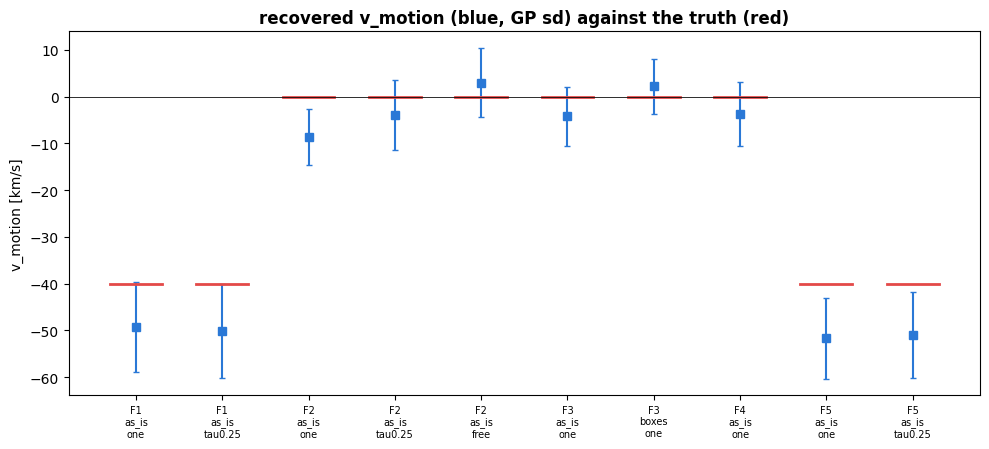

In [27]:
if CL:
    th_true = np.array([[kw_.get("hv0"), 
                         kw_.get("alpha_conds"), 
                         kw_.get("alpha_hv"), 
                         kw_.get("f_ion", 0.0)] for kw_ in [CL[0]["kw"]]], float)
    
    print(f"Truth model theta (hv0, alpha_conds, alpha_hv, f_ion) = {np.round(th_true[0], 3)}; "
          f"hv_pivot = {feat.hv_pivot(np.c_[th_true, [0.0]])[0]:.1f}")
    
    print(f"\n{'scenario':34s} {'rep':>3s} {'policy':>7s} {'norm':>7s} | {'true v':>7s} "
          f"{'recovered v_motion':>20s} {'hv_pivot':>16s} {'alpha_conds':>16s} {'alpha_hv':>16s} | "
          f"{'M1 over G1 (best 10)':>22s}")
    
    for r in CL:
        print(f"{r['sc'] + ' ' + r['name']:34s} {r['rep']:3d} {r['pol']:>7s} {r['norm']:>7s} | " + \
              f"{r['v_true']:+7.0f} {cellv(r['o'], 'motion', 'v_motion', 20)} " + \
              " ".join(cellv(r['o'], 'motion', c, 16) for c in ("hv_pivot", "alpha_conds", "alpha_hv")) + \
              f" | {r['gain']:+8.2f}% ({r['gain_u']:+5.1f} u)")
        
    fig, ax = plt.subplots(figsize=(10, 4.6))
    lbl = []
    for i, r in enumerate(CL):
        m_, s_ = opt_val(r["o"], "motion", "v_motion")
        ax.errorbar([i], [m_], yerr=[s_], fmt="s", ms=6, capsize=2, color="#2a78d6")
        ax.plot([i - 0.3, i + 0.3], [r["v_true"]] * 2, "-", color="#e34948", lw=2)
        lbl.append(f"{r['sc']}\n{r['pol']}\n{r['norm']}")

    ax.set_xticks(range(len(CL)))
    ax.set_xticklabels(lbl, fontsize=7)
    ax.axhline(0, color="#0b0b0b", lw=0.6)
    ax.set_ylabel("v_motion [km/s]")
    ax.set_title("recovered v_motion (blue, GP sd) against the truth (red)", weight="bold")

    plt.tight_layout()
    plt.show()

**Reading it.** 

F4 and the *one scale* rows of F2 and F3 are the false-positive tests: a recovered $v_{\rm motion}$ far below zero with a gain of `M1` over `G1` of several $u$ means that a normalization difference or a mask artefact is read as a wind. Although there is some fluctuations around the truth, we see that this not the case.

The same scenarios under the prior ($\tau$ = 0.25), a free ratio or a policy that removes the artefact (`boxes`) say what protects the inference. We see that the recovery is indeed, perhaps positively, affected by these choices.

F1 is the recovery: if the truth $-40$ is returned with a GP error of $\pm 10-20$, the data can see a wind of that size at this noise. If F5 returns something far from $-40$ with a small error, the south factor is being read as wind. We see that the find can be recovered, but there is a more visible drift. Because each is one draw, it cannot show a spread, but we can be informed about the bias it has.

## What did we learn?

* We see that a masking choice of `boxes` or above affects the parameters, but would also be a logical choice to include from hereon out.
* Robust parameters are not effected by the difference between the north and south hemispheres, are affected limitedly by a prior choice, have limited L/H mixing, and can recover truths from a mock model.
* We see the opposite for non-robust parameters, and this is something we should be careful of, so that we can avoid it in the Bayesian step.